# Project 2.2: Bidirectional Image–Text Retrieval with Multimodal Learning

**Complete group implementation in execution order:** COCO data preparation and frozen feature extraction → InfoNCE (Model A) → Triplet Ranking (Model B) → Early Fusion (Model C) → common validation and held-out test comparison.

This combines the four original experiment notebooks. Model training procedures, loss functions and reported results are preserved. The merged copy includes small compatibility fixes for archive extraction, path handling and selected-model loading, plus team-oriented section descriptions.

**Execution:** Run **Restart and Run All** in Colab (T4 recommended) or a compatible Python environment. Internet access is required for the initial COCO and pretrained-encoder downloads. The existing outputs below were recorded in the separate source notebooks; they are **not evidence that this merged notebook has been run end-to-end**. The final test data are accessed only in the common comparison section.


---

## 1. Dataset preparation, ResNet-50/BERT features, and InfoNCE (Model A)

*Source notebook: `Member_1_COCO_InfoNCE_Clean(1).ipynb`. The cells below are preserved as submitted.*

# COCO Dataset Preparation and InfoNCE Model

This section covers the shared COCO preprocessing and feature extraction pipeline and the InfoNCE retrieval baseline.

- Audit and clean captions, then create image-disjoint train, validation and test splits.
- Extract frozen ResNet-50 image features and mean-pooled BERT caption features.
- Train InfoNCE projections across three seeds, assess retrieval and generalisation, and export checkpoints and evidence.

Generated files are stored in `./multimodal_project/`. The held-out test set is reserved for the common final model comparison.


## 1. Environment and reproducible configuration

Dependencies: PyTorch + torchvision, Hugging Face `datasets` and `transformers`, Pillow, NumPy, matplotlib. Pretrained encoder downloads require internet on the first run. The following cell installs missing packages only, without changing an existing PyTorch/CUDA installation.

In [1]:
import importlib.util
import subprocess
import sys

for module, package in [
    ("torch", "torch"),
    ("torchvision", "torchvision"),
    ("datasets", "datasets"),
    ("transformers", "transformers"),
    ("PIL", "Pillow"),
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
]:
    if importlib.util.find_spec(module) is None:
        print(f"Installing missing package: {package}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

from pathlib import Path
from collections import Counter, defaultdict
from zipfile import ZipFile, ZIP_STORED, ZIP_DEFLATED
import json, random, hashlib, time, gc, platform
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from datasets import load_dataset, Image
from torchvision.models import resnet50, ResNet50_Weights
from transformers import AutoTokenizer, AutoModel

PROJECT = Path.cwd() / "multimodal_project"
DATA = PROJECT / "shared_data"
MODELS = PROJECT / "models"
RESULTS = PROJECT / "results"
for directory in (DATA, MODELS, RESULTS):
    directory.mkdir(parents=True, exist_ok=True)

DATASET = "lmms-lab/COCO-Caption2017"
DATA_SPLIT = "val"
SPLIT_SEED = 42
RUN_SEEDS = [42, 43, 44]            # Three reproducibility runs as promised in proposal
TRAIN_N, VAL_N, TEST_N = 4000, 500, 500
EMBED_DIM, BATCH_SIZE = 256, 128
LR, WEIGHT_DECAY, TEMP = 1e-3, 0.01, 0.07
MAX_EPOCHS, PATIENCE = 30, 7
MAX_TOKENS, IMAGE_BATCH, TEXT_BATCH = 64, 16, 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


print("Device:", DEVICE)
print("Dataset splits:", TRAIN_N, VAL_N, TEST_N)
print("Random seeds:", RUN_SEEDS)


Device: cuda
Dataset splits: 4000 500 500
Random seeds: [42, 43, 44]


## 2. Dataset cleaning, audit and reproducible splits

Keep all captions for each image in the same split. Remove empty and known non-descriptive placeholder captions only. **Do not delete legitimate repeated captions**: they can refer to different images and need special handling in training/evaluation. Retain licence metadata; do not redistribute original images.

In [2]:
placeholder = "there is no image here to provide a caption for."
stream = load_dataset(DATASET, split=DATA_SPLIT, streaming=True)
stream = stream.cast_column("image", Image(decode=False))
records, removed_examples = [], []

for row in stream:
    cleaned = []
    for caption in (row["answer"] or []):
        if not isinstance(caption, str) or not caption.strip() or caption.strip().casefold() == placeholder:
            removed_examples.append({"image_id": int(row["id"]), "caption": str(caption)})
        else:
            cleaned.append(caption.strip())
    records.append({
        "id": int(row["id"]),
        "file_name": str(row["file_name"]),
        "width": int(row["width"]),
        "height": int(row["height"]),
        "license": str(row["license"]),
        "captions": cleaned
    })

assert len(records) == 5000, f"Unexpected dataset size: {len(records)}"
assert len({r["id"] for r in records}) == 5000, "Duplicate image IDs"
assert all(r["captions"] for r in records), "An image lost all valid captions"

all_captions = [c for r in records for c in r["captions"]]
caption_owners = defaultdict(set)
for r in records:
    for c in r["captions"]:
        caption_owners[c.strip().casefold()].add(r["id"])

cross_image_duplicates = {c: sorted(ids) for c, ids in caption_owners.items() if len(ids) > 1}
lengths = [len(c.split()) for c in all_captions]
audit = {
    "dataset": DATASET,
    "source_split": DATA_SPLIT,
    "image_count": len(records),
    "valid_caption_count": len(all_captions),
    "removed_captions": removed_examples,
    "mean_words_per_caption": float(np.mean(lengths)),
    "median_words_per_caption": float(np.median(lengths)),
    "caption_counts_per_image": dict(Counter(str(len(r["captions"])) for r in records)),
    "duplicate_caption_occurrences": len(all_captions) - len(set(all_captions)),
    "cross_image_duplicate_texts": len(cross_image_duplicates),
    "sample_cross_image_duplicates": dict(list(cross_image_duplicates.items())[:8]),
    "width_min_max": [min(r["width"] for r in records), max(r["width"] for r in records)],
    "height_min_max": [min(r["height"] for r in records), max(r["height"] for r in records)],
    "license_code_counts": dict(Counter(r["license"] for r in records)),
    "notes": "Image licences are not all the same; verify licences before publishing any images."
}

shuffled = records.copy()
random.Random(SPLIT_SEED).shuffle(shuffled)
splits = {
    "train": shuffled[:TRAIN_N],
    "validation": shuffled[TRAIN_N:TRAIN_N+VAL_N],
    "test": shuffled[TRAIN_N+VAL_N:]
}
assert [len(splits[k]) for k in ("train", "validation", "test")] == [4000, 500, 500]
ids_by_split = {k: {r["id"] for r in v} for k, v in splits.items()}
assert ids_by_split["train"].isdisjoint(ids_by_split["validation"])
assert ids_by_split["train"].isdisjoint(ids_by_split["test"])
assert ids_by_split["validation"].isdisjoint(ids_by_split["test"])

with (DATA / "coco_splits.json").open("w", encoding="utf-8") as f:
    json.dump(splits, f, indent=2, ensure_ascii=False)
with (RESULTS / "dataset_audit.json").open("w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2, ensure_ascii=False)


print("Images:", audit["image_count"])
print("Valid captions:", audit["valid_caption_count"])
print("Invalid captions removed:", len(removed_examples))
print("Mean caption length:", round(audit["mean_words_per_caption"], 2))
print("Repeated captions across images:", audit["cross_image_duplicate_texts"])

for name, rows in splits.items():
    print(f"{name}: {len(rows)} images")


README.md:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

Images: 5000
Valid captions: 25010
Invalid captions removed: 4
Mean caption length: 10.44
Repeated captions across images: 121
train: 4000 images
validation: 500 images
test: 500 images


## 3. Frozen ResNet-50/BERT feature extraction

The same **frozen and cached** features will be reused by all models. ResNet-50 produces 2,048-D image features; BERT mean-pooling with the attention mask produces 768-D caption features. Both models are used only for feature extraction. No validation/test example is used to fit encoders or projections.

In [3]:
weights = ResNet50_Weights.DEFAULT
image_transform = weights.transforms()
image_encoder = resnet50(weights=weights)
image_encoder.fc = nn.Identity()
image_encoder = image_encoder.to(DEVICE).eval()

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
text_encoder = AutoModel.from_pretrained("bert-base-uncased").to(DEVICE).eval()

for encoder in (image_encoder, text_encoder):
    for parameter in encoder.parameters():
        parameter.requires_grad_(False)

print("ResNet-50: 2048-D", "| BERT: 768-D", "| frozen encoders ready")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 173MB/s]


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ResNet-50: 2048-D | BERT: 768-D | frozen encoders ready


In [4]:
all_records = splits["train"] + splits["validation"] + splits["test"]
image_ids = [r["id"] for r in all_records]
image_index = {image_id: pos for pos, image_id in enumerate(image_ids)}
assert len(image_index) == 5000

image_feature_path = DATA / "image_features.pt"
start = time.perf_counter()
if image_feature_path.exists():
    print("Image cache already exists; checking it instead of recomputing.")
    image_package = torch.load(image_feature_path, map_location="cpu", weights_only=True)
    assert image_package["image_ids"] == image_ids
    assert image_package["features"].shape == (5000, 2048)
else:
    image_features = torch.empty((5000, 2048), dtype=torch.float32)
    seen = set()
    queued_images, queued_indices = [], []

    def flush_images():
        if not queued_images:
            return
        batch = torch.stack(queued_images).to(DEVICE)
        with torch.inference_mode():
            values = image_encoder(batch).float().cpu()
        image_features[queued_indices] = values
        queued_images.clear()
        queued_indices.clear()

    image_stream = load_dataset(DATASET, split=DATA_SPLIT, streaming=True)
    for row in image_stream:
        image_id = int(row["id"])
        if image_id not in image_index:
            continue
        assert image_id not in seen, f"Duplicate ID in streamed images: {image_id}"
        seen.add(image_id)
        queued_images.append(image_transform(row["image"].convert("RGB")))
        queued_indices.append(image_index[image_id])
        if len(queued_images) >= IMAGE_BATCH:
            flush_images()
        if len(seen) % 500 == 0:
            print("Images processed:", len(seen), "/ 5000")
    flush_images()
    assert len(seen) == 5000
    assert torch.isfinite(image_features).all()
    torch.save({
        "features": image_features,
        "image_ids": image_ids,
        "encoder": "ResNet50_Weights.DEFAULT",
        "dimensions": 2048,
    }, image_feature_path)
    del image_features
    image_package = torch.load(image_feature_path, map_location="cpu", weights_only=True)

print("Image features:", tuple(image_package["features"].shape))
print("Saved:", image_feature_path, "| elapsed:", round(time.perf_counter()-start, 2), "seconds")

Images processed: 500 / 5000
Images processed: 1000 / 5000
Images processed: 1500 / 5000
Images processed: 2000 / 5000
Images processed: 2500 / 5000
Images processed: 3000 / 5000
Images processed: 3500 / 5000
Images processed: 4000 / 5000
Images processed: 4500 / 5000
Images processed: 5000 / 5000
Image features: (5000, 2048)
Saved: /content/multimodal_project/shared_data/image_features.pt | elapsed: 85.67 seconds


In [5]:
text_feature_path = DATA / "text_features.pt"
all_captions, caption_image_indices, caption_splits = [], [], []
for split_name, start_idx, rows in [
    ("train", 0, splits["train"]),
    ("validation", TRAIN_N, splits["validation"]),
    ("test", TRAIN_N + VAL_N, splits["test"]),
]:
    for local_idx, row in enumerate(rows):
        for caption in row["captions"]:
            all_captions.append(caption)
            caption_image_indices.append(start_idx + local_idx)
            caption_splits.append(split_name)

start = time.perf_counter()
if text_feature_path.exists():
    print("Text cache already exists; checking it instead of recomputing.")
    text_package = torch.load(text_feature_path, map_location="cpu", weights_only=True)
    assert text_package["captions"] == all_captions
    assert text_package["caption_image_indices"] == caption_image_indices
    assert text_package["features"].shape == (len(all_captions), 768)
else:
    text_parts = []
    for pos in range(0, len(all_captions), TEXT_BATCH):
        batch_texts = all_captions[pos:pos+TEXT_BATCH]
        token_batch = tokenizer(
            batch_texts, padding=True, truncation=True,
            max_length=MAX_TOKENS, return_tensors="pt"
        ).to(DEVICE)
        with torch.inference_mode():
            states = text_encoder(**token_batch).last_hidden_state
            mask = token_batch["attention_mask"].unsqueeze(-1)
            pooled = (states * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
            text_parts.append(pooled.float().cpu())
        if pos and (pos // TEXT_BATCH) % 40 == 0:
            print("Captions processed:", pos, "/", len(all_captions))
    text_features = torch.cat(text_parts)
    assert torch.isfinite(text_features).all()
    torch.save({
        "features": text_features,
        "captions": all_captions,
        "caption_image_indices": caption_image_indices,
        "caption_splits": caption_splits,
        "encoder": "bert-base-uncased",
        "pooling": "masked_mean",
        "max_length": MAX_TOKENS,
    }, text_feature_path)
    del text_features, text_parts
    text_package = torch.load(text_feature_path, map_location="cpu", weights_only=True)

assert len(all_captions) == sum(len(r["captions"]) for r in all_records)
print("Caption features:", tuple(text_package["features"].shape))
print("Saved:", text_feature_path, "| elapsed:", round(time.perf_counter()-start, 2), "seconds")

Captions processed: 2560 / 25010
Captions processed: 5120 / 25010
Captions processed: 7680 / 25010
Captions processed: 10240 / 25010
Captions processed: 12800 / 25010
Captions processed: 15360 / 25010
Captions processed: 17920 / 25010
Captions processed: 20480 / 25010
Captions processed: 23040 / 25010
Caption features: (25010, 768)
Saved: /content/multimodal_project/shared_data/text_features.pt | elapsed: 32.04 seconds


## 4. Verify and Export Shared Dataset

Verify alignment between image identifiers, captions, and split membership. The exported package includes `coco_splits.json`, cached ResNet-50/BERT features and the dataset audit; raw images are not redistributed. The same shared data are used across the retrieval approaches.


In [6]:
images = torch.load(image_feature_path, map_location="cpu", weights_only=True)
texts = torch.load(text_feature_path, map_location="cpu", weights_only=True)
assert images["image_ids"] == image_ids
assert texts["captions"] == all_captions
assert texts["caption_image_indices"] == caption_image_indices
assert images["features"].shape == (5000, 2048)
assert texts["features"].shape == (len(all_captions), 768)
assert min(caption_image_indices) == 0 and max(caption_image_indices) == 4999
assert all(caption_splits[j] == ("train" if i < 4000 else "validation" if i < 4500 else "test")
           for j, i in enumerate(caption_image_indices))

shared_zip = PROJECT / "multimodal_shared_data.zip"
with ZipFile(shared_zip, "w", ZIP_STORED) as z:
    for p in [DATA / "coco_splits.json", image_feature_path, text_feature_path, RESULTS / "dataset_audit.json"]:
        z.write(p, arcname=str(p.relative_to(PROJECT)))

print("Shared package:", shared_zip)
print("Size (MB):", round(shared_zip.stat().st_size / 1024**2, 2))


Shared package: /content/multimodal_project/multimodal_shared_data.zip
Size (MB): 116.34


## 5. InfoNCE Model A: architecture, training and validation

- Frozen encoders; only the 2 projection layers are trained.
- One randomly selected caption per distinct training image in each batch.
- Duplicate caption strings are masked as in-batch false negatives.
- Checkpoints selected by **validation** average Recall@1; test data is never used for model selection.
- Repeat with seeds 42, 43, 44; save training histories and best weights for each run.

**Evaluation protocol:** fixed 500-image gallery and all its captions. The primary score recognises **identical caption text shared across gallery images** as ambiguous valid matches; strict original-image scores are also recorded for transparency. For image→text, any caption describing the image is correct. For text→image, any gallery image carrying that identical caption text is accepted for the ambiguity-aware metric. All methods in the group must use the same convention.

In [7]:
# Once cached, release encoder GPU memory. We train only projections below.
del image_encoder, text_encoder
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

X_img = images["features"].float().to(DEVICE)
X_txt = texts["features"].float().to(DEVICE)
caption_to_image = torch.tensor(texts["caption_image_indices"], dtype=torch.long, device=DEVICE)
caption_keys = [str(c).strip().casefold() for c in texts["captions"]]
unique_keys = {key: i for i, key in enumerate(dict.fromkeys(caption_keys))}
key_ids = torch.tensor([unique_keys[k] for k in caption_keys], dtype=torch.long, device=DEVICE)
image_to_caption = [[] for _ in range(5000)]
for ci, img_i in enumerate(texts["caption_image_indices"]):
    image_to_caption[img_i].append(ci)
assert all(image_to_caption[i] for i in range(5000))

train_ids = list(range(4000))
val_ids = torch.arange(4000, 4500, device=DEVICE)
val_caption_ids = torch.where((caption_to_image >= 4000) & (caption_to_image < 4500))[0]

class InfoNCEModel(nn.Module):
    def __init__(self, dimension=EMBED_DIM):
        super().__init__()
        self.image_projection = nn.Linear(2048, dimension)
        self.text_projection = nn.Linear(768, dimension)

    def forward(self, x_image, x_text):
        return (F.normalize(self.image_projection(x_image), dim=-1),
                F.normalize(self.text_projection(x_text), dim=-1))


def recall_mrr(similarity, correct):
    """True if ANY valid caption/image occurs in top-k; returns R@k and MRR."""
    order = similarity.argsort(dim=1, descending=True)
    hits = correct.gather(1, order)
    assert hits.any(dim=1).all(), "Some retrieval queries have no eligible correct result"
    first = hits.to(torch.int32).argmax(dim=1) + 1
    return {f"R@{k}": float((first <= k).float().mean()) for k in (1, 5, 10)} | {
        "MRR": float((1.0 / first.float()).mean())
    }


def retrieval_metrics(model, gallery_images, gallery_captions, include_strict=False):
    """Unified retrieval protocol; gallery uses all legitimate captions."""
    model.eval()
    with torch.inference_mode():
        a = F.normalize(model.image_projection(X_img[gallery_images]), dim=-1)
        b = F.normalize(model.text_projection(X_txt[gallery_captions]), dim=-1)
        similarities = a @ b.T
        truth = gallery_images[:, None].eq(caption_to_image[gallery_captions][None, :])
        strict = {
            "image_to_text": recall_mrr(similarities, truth),
            "text_to_image": recall_mrr(similarities.T, truth.T),
        }
        # Identical text belonging to distinct gallery images is ambiguous.
        # Accept any of those gallery images (both retrieval directions).
        ambiguous = truth.clone()
        owner_by_key = defaultdict(set)
        for image_i, cap_i in zip(
            caption_to_image[gallery_captions].tolist(), gallery_captions.tolist()
        ):
            owner_by_key[caption_keys[cap_i]].add(image_i)
        gallery_ids = gallery_images.tolist()
        for col, cap_i in enumerate(gallery_captions.tolist()):
            owners = owner_by_key[caption_keys[cap_i]]
            if len(owners) > 1:
                ambiguous[:, col] |= torch.tensor(
                    [image_i in owners for image_i in gallery_ids],
                    dtype=torch.bool, device=DEVICE
                )
        broad = {
            "image_to_text": recall_mrr(similarities, ambiguous),
            "text_to_image": recall_mrr(similarities.T, ambiguous.T)
        }
    result = {"ambiguous_aware": broad}
    if include_strict:
        result["strict_origin"] = strict
    return result


print("Model A parameters:", sum(p.numel() for p in InfoNCEModel().parameters()))
print("Validation gallery:", len(val_ids), "images and", len(val_caption_ids), "captions")

Model A parameters: 721408
Validation gallery: 500 images and 2499 captions


In [8]:
def train_one_seed(seed):
    torch.manual_seed(seed)
    random.seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    sampler = random.Random(seed)
    model = InfoNCEModel().to(DEVICE)
    optim = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    run_history = []
    no_gain, best_score, best_epoch = 0, -1.0, None
    best_path = MODELS / f"infonce_seed_{seed}_best.pt"
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(TRAIN_N).tolist()
        losses = []
        for pos in range(0, TRAIN_N, BATCH_SIZE):
            ids = order[pos:pos+BATCH_SIZE]
            cap_ids = [sampler.choice(image_to_caption[image_i]) for image_i in ids]
            ix = torch.tensor(ids, dtype=torch.long, device=DEVICE)
            cx = torch.tensor(cap_ids, dtype=torch.long, device=DEVICE)
            a, b = model(X_img[ix], X_txt[cx])
            scores = a @ b.T / TEMP
            same_text = key_ids[cx, None].eq(key_ids[None, cx])
            eye = torch.eye(len(ids), dtype=torch.bool, device=DEVICE)
            scores = scores.masked_fill(same_text & ~eye, -1e4)
            labels = torch.arange(len(ids), device=DEVICE)
            loss = (F.cross_entropy(scores, labels) + F.cross_entropy(scores.T, labels)) / 2
            optim.zero_grad(set_to_none=True)
            loss.backward()
            optim.step()
            losses.append(float(loss.detach()))

        val = retrieval_metrics(model, val_ids, val_caption_ids)["ambiguous_aware"]
        ri = val["image_to_text"]["R@1"]
        rt = val["text_to_image"]["R@1"]
        score = (ri + rt) / 2
        run_history.append({
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "val_i2t_r1": ri,
            "val_t2i_r1": rt,
            "val_average_r1": score
        })
        print(f"Seed {seed} | Epoch {epoch:02d} | loss={np.mean(losses):.4f} | "
              f"val I2T R@1={ri:.2%} | T2I R@1={rt:.2%}")
        if score > best_score + 1e-6:
            best_score, best_epoch, no_gain = score, epoch, 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "best_epoch": epoch,
                "validation_avg_r1": score,
                "seed": seed,
                "embedding_dim": EMBED_DIM
            }, best_path)
        else:
            no_gain += 1
        if no_gain >= PATIENCE:
            print("Early stopping for seed", seed)
            break
    with (RESULTS / f"infonce_history_seed_{seed}.json").open("w") as f:
        json.dump(run_history, f, indent=2)
    return {"seed": seed, "best_epoch": best_epoch,
            "best_val_average_r1": best_score,
            "elapsed_train_seconds": time.perf_counter()-started,
            "checkpoint": str(best_path),
            "epochs_run": len(run_history)}

run_summaries = []
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
for seed in RUN_SEEDS:
    run_summaries.append(train_one_seed(seed))

best_run = max(run_summaries, key=lambda x: x["best_val_average_r1"])


for r in run_summaries:
    print("Seed:", r["seed"],
          "| Best epoch:", r["best_epoch"],
          "| Validation R@1:", f'{r["best_val_average_r1"]:.2%}')

print("Mean R@1:", f'{np.mean([r["best_val_average_r1"] for r in run_summaries]):.2%}')
print("SD:", f'{np.std([r["best_val_average_r1"] for r in run_summaries], ddof=1):.2%}')
print("Best seed:", best_run["seed"])


Seed 42 | Epoch 01 | loss=2.5842 | val I2T R@1=25.00% | T2I R@1=19.93%
Seed 42 | Epoch 02 | loss=1.4524 | val I2T R@1=27.20% | T2I R@1=21.77%
Seed 42 | Epoch 03 | loss=1.1972 | val I2T R@1=30.80% | T2I R@1=24.45%
Seed 42 | Epoch 04 | loss=1.0760 | val I2T R@1=31.60% | T2I R@1=24.97%
Seed 42 | Epoch 05 | loss=0.9565 | val I2T R@1=33.80% | T2I R@1=25.89%
Seed 42 | Epoch 06 | loss=0.8598 | val I2T R@1=36.60% | T2I R@1=26.57%
Seed 42 | Epoch 07 | loss=0.8065 | val I2T R@1=32.40% | T2I R@1=24.93%
Seed 42 | Epoch 08 | loss=0.7687 | val I2T R@1=33.40% | T2I R@1=26.21%
Seed 42 | Epoch 09 | loss=0.7193 | val I2T R@1=37.20% | T2I R@1=25.85%
Seed 42 | Epoch 10 | loss=0.6881 | val I2T R@1=35.00% | T2I R@1=27.45%
Seed 42 | Epoch 11 | loss=0.6578 | val I2T R@1=36.20% | T2I R@1=26.65%
Seed 42 | Epoch 12 | loss=0.6091 | val I2T R@1=33.80% | T2I R@1=25.65%
Seed 42 | Epoch 13 | loss=0.5808 | val I2T R@1=34.80% | T2I R@1=27.29%
Early stopping for seed 42
Seed 43 | Epoch 01 | loss=2.5752 | val I2T R@1=27.

## 6. Validation Metrics, Generalisation and Error Analysis

Measure Recall@1/5/10 and mean reciprocal rank in both directions. Compare 500 training and 500 validation images using equal-sized image galleries with their associated captions. A large train–validation gap suggests potential overfitting but does not constitute a formal significance test. The held-out test is used only for the final common comparison.


In [9]:
best_checkpoint = torch.load(best_run["checkpoint"], map_location=DEVICE, weights_only=True)
best_model = InfoNCEModel().to(DEVICE)
best_model.load_state_dict(best_checkpoint["model_state_dict"])
best_model.eval()

# 500 unique reproducible training images (not selected for model fitting).
train_rng = torch.Generator().manual_seed(SPLIT_SEED)
train_500 = torch.randperm(TRAIN_N, generator=train_rng)[:500].to(DEVICE)
train_500_captions = torch.where(torch.isin(caption_to_image, train_500))[0]

train_eval = retrieval_metrics(best_model, train_500, train_500_captions, include_strict=True)
val_eval = retrieval_metrics(best_model, val_ids, val_caption_ids, include_strict=True)

print("=== BEST SEED", best_run["seed"], "| EPOCH", best_run["best_epoch"], "===")
for direction in ("image_to_text", "text_to_image"):
    print("\n", direction)
    for metric in ("R@1", "R@5", "R@10", "MRR"):
        tr = train_eval["ambiguous_aware"][direction][metric]
        vl = val_eval["ambiguous_aware"][direction][metric]
        print(f"{metric:<5} train={tr:.2%} val={vl:.2%} gap={(tr-vl)*100:.2f} pp")
print("\nSTRICT (original image IDs) validation:", val_eval["strict_origin"])
print("Test gallery not evaluated")

report = {
    "selected_seed": best_run["seed"],
    "selected_epoch": best_run["best_epoch"],
    "selection_based_on": "validation mean Recall@1; test not used",
    "runs": run_summaries,
    "train_500": train_eval,
    "validation_500": val_eval,
    "evaluation_gallery": {"images": 500, "validation_captions": len(val_caption_ids)},
    "limitations": [
        "Train retrieval is in-sample; validation is held-out.",
        "Duplicate-aware metrics count identical captions as valid for all owning images.",
        "Frozen encoders and small COCO split may limit generalisation to new domains."
    ]
}
with (RESULTS / "infonce_analysis.json").open("w") as f:
    json.dump(report, f, indent=2)

# Preserve a copy of the best selected model under a stable path
import shutil
shutil.copy2(best_run["checkpoint"], MODELS / "infonce_best.pt")

=== BEST SEED 44 | EPOCH 9 ===

 image_to_text
R@1   train=76.60% val=38.80% gap=37.80 pp
R@5   train=96.20% val=69.40% gap=26.80 pp
R@10  train=99.00% val=83.20% gap=15.80 pp
MRR   train=85.30% val=52.63% gap=32.67 pp

 text_to_image
R@1   train=62.88% val=28.29% gap=34.59 pp
R@5   train=92.40% val=67.71% gap=24.69 pp
R@10  train=97.48% val=83.11% gap=14.37 pp
MRR   train=75.67% val=45.26% gap=30.41 pp

STRICT (original image IDs) validation: {'image_to_text': {'R@1': 0.3880000114440918, 'R@5': 0.6940000057220459, 'R@10': 0.8320000171661377, 'MRR': 0.5262500047683716}, 'text_to_image': {'R@1': 0.28251299262046814, 'R@5': 0.6758703589439392, 'R@10': 0.8307322859764099, 'MRR': 0.45198342204093933}}
Test gallery not evaluated


PosixPath('/content/multimodal_project/models/infonce_best.pt')

In [10]:
# Representative validation successes and failures using image IDs / caption text only.
with torch.inference_mode():
    gallery_image = F.normalize(best_model.image_projection(X_img[val_ids]), dim=1)
    gallery_text = F.normalize(best_model.text_projection(X_txt[val_caption_ids]), dim=1)
    similarities = gallery_image @ gallery_text.T
    owner_indices = caption_to_image[val_caption_ids]
    image_ranked = similarities.argsort(dim=1, descending=True)

examples = {"image_to_text_success": [], "image_to_text_failure": []}
for row, image_i in enumerate(val_ids.tolist()):
    predicted_c = val_caption_ids[image_ranked[row, 0]].item()
    predicted_text = texts["captions"][predicted_c]
    gold_keys = {caption_keys[c] for c in image_to_caption[image_i]}
    correct = caption_keys[predicted_c] in gold_keys
    bucket = "image_to_text_success" if correct else "image_to_text_failure"
    if len(examples[bucket]) < 8:
        examples[bucket].append({
            "query_image_id": image_ids[image_i],
            "retrieved_caption": predicted_text,
            "reference_captions": all_records[image_i]["captions"][:3],
            "cosine_similarity": round(float(similarities[row, image_ranked[row, 0]]), 4)
        })

with (RESULTS / "infonce_retrieval_examples.json").open("w", encoding="utf-8") as f:
    json.dump(examples, f, indent=2, ensure_ascii=False)
print("Examples saved:", {k: len(v) for k, v in examples.items()})
print("Example failure:", examples["image_to_text_failure"][:1])

Examples saved: {'image_to_text_success': 8, 'image_to_text_failure': 8}
Example failure: [{'query_image_id': 215958, 'retrieved_caption': 'A kitchen looks very clean with corner cabinets.', 'reference_captions': ['A kitchen with a counter and a table with chairs.', 'A large dining room features wooden cabinets and a marble counter top.', 'a black counter a sink and a table and two chairs'], 'cosine_similarity': 0.5871}]


## 7. Figures, Configuration and Export

Generate training-loss, validation Recall@1 and generalisation plots. Store checkpoints, experimental configuration, software versions, metrics and supporting figures for the final cross-model analysis. Keep source code in the project repository and store large feature archives separately.


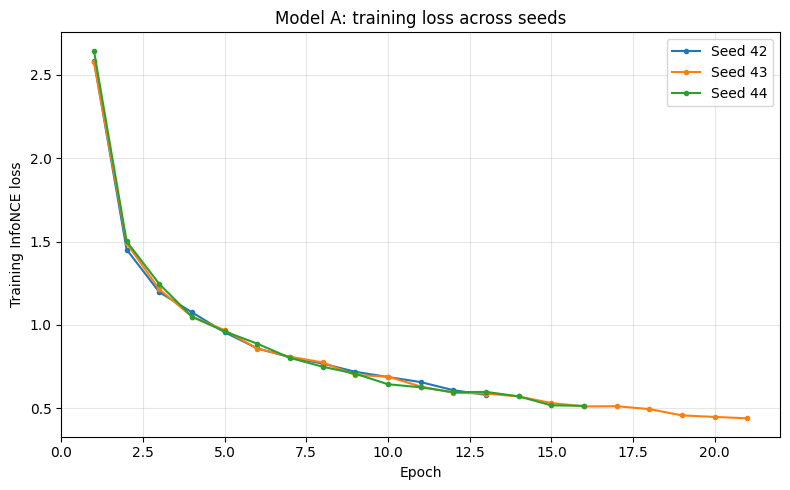

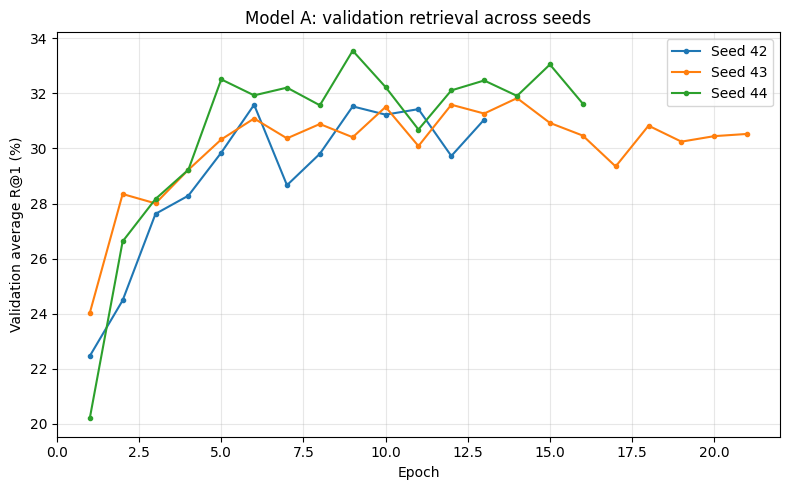

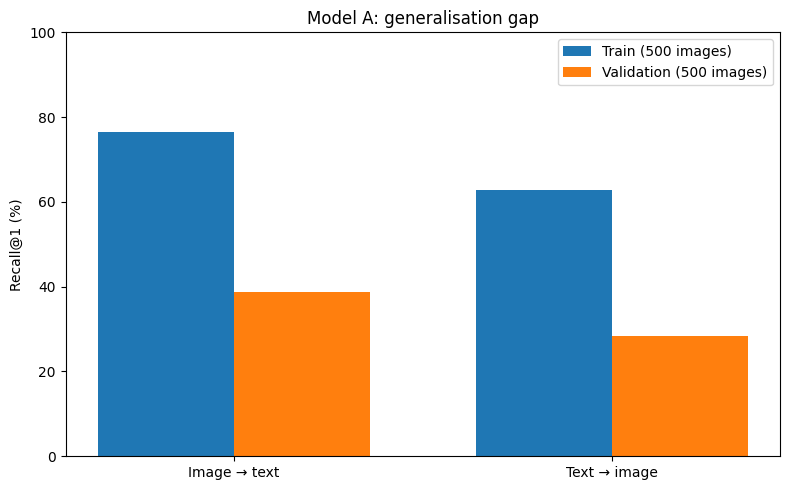

Saved three Model A figures to: /content/multimodal_project/results


In [11]:
# Training curves for all 3 seeds
fig, ax = plt.subplots(figsize=(8, 5))
for seed in RUN_SEEDS:
    with (RESULTS / f"infonce_history_seed_{seed}.json").open() as f:
        h = json.load(f)
    ax.plot([v["epoch"] for v in h], [v["train_loss"] for v in h], marker=".", label=f"Seed {seed}")
ax.set(xlabel="Epoch", ylabel="Training InfoNCE loss", title="Model A: training loss across seeds")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "infonce_training_loss.png", dpi=250)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for seed in RUN_SEEDS:
    with (RESULTS / f"infonce_history_seed_{seed}.json").open() as f:
        h = json.load(f)
    ax.plot([v["epoch"] for v in h], [v["val_average_r1"]*100 for v in h], marker=".", label=f"Seed {seed}")
ax.set(xlabel="Epoch", ylabel="Validation average R@1 (%)", title="Model A: validation retrieval across seeds")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "infonce_validation_recall.png", dpi=250)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Image → text", "Text → image"]
tr = [train_eval["ambiguous_aware"][d]["R@1"]*100 for d in ("image_to_text", "text_to_image")]
va = [val_eval["ambiguous_aware"][d]["R@1"]*100 for d in ("image_to_text", "text_to_image")]
x = np.arange(len(labels))
ax.bar(x - 0.18, tr, width=0.36, label="Train (500 images)")
ax.bar(x + 0.18, va, width=0.36, label="Validation (500 images)")
ax.set(xticks=x, xticklabels=labels, ylim=(0,100), ylabel="Recall@1 (%)", title="Model A: generalisation gap")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "infonce_overfitting.png", dpi=250)
plt.show()
print("Saved three Model A figures to:", RESULTS)

In [12]:
import torchvision, transformers, datasets
configuration = {
    "scope": "COCO dataset preparation, frozen features and InfoNCE retrieval",
    "dataset": DATASET, "dataset_split": DATA_SPLIT,
    "split_seed": SPLIT_SEED, "image_counts": [TRAIN_N, VAL_N, TEST_N],
    "seeds": RUN_SEEDS, "image_encoder": "ResNet50_Weights.DEFAULT",
    "text_encoder": "bert-base-uncased", "text_pooling": "masked_mean",
    "token_max_length": MAX_TOKENS,
    "image_dimensions": 2048, "text_dimensions": 768,
    "projection_dimensions": EMBED_DIM, "batch_size": BATCH_SIZE,
    "learning_rate": LR, "weight_decay": WEIGHT_DECAY,
    "InfoNCE_temperature": TEMP, "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "caption_sampling": "one caption per image per batch, random each epoch",
    "duplicate_handling": "mask identical caption negative pairs",
    "validation_rule": "duplicate-aware primary, strict-origin secondary",
    "best_seed": best_run["seed"], "best_epoch": best_run["best_epoch"],
    "python_version": platform.python_version(),
    "torch_version": torch.__version__, "torchvision_version": torchvision.__version__,
    "datasets_version": datasets.__version__, "transformers_version": transformers.__version__,
    "split_sha256": hashlib.sha256((DATA / "coco_splits.json").read_bytes()).hexdigest(),
    "test_untouched": True
}
with (MODELS / "infonce_config.json").open("w") as f:
    json.dump(configuration, f, indent=2)

model_zip = PROJECT / "InfoNCE_Model_A.zip"
model_files = ([MODELS / "infonce_best.pt", MODELS / "infonce_config.json"]
               + [MODELS / f"infonce_seed_{seed}_best.pt" for seed in RUN_SEEDS]
               + sorted(RESULTS.glob("infonce_*.json"))
               + sorted(RESULTS.glob("infonce_*.png")))
assert all(p.exists() for p in model_files)
with ZipFile(model_zip, "w", ZIP_DEFLATED) as z:
    for p in model_files:
        z.write(p, arcname=str(p.relative_to(PROJECT)))

print("Shared feature package:", shared_zip, "(", round(shared_zip.stat().st_size / 1024**2, 2), "MB)")
print("Model A package:", model_zip, "(", round(model_zip.stat().st_size / 1024**2, 2), "MB)")


Shared feature package: /content/multimodal_project/multimodal_shared_data.zip ( 116.34 MB)
Model A package: /content/multimodal_project/InfoNCE_Model_A.zip ( 10.52 MB)



### Project Outputs

The following files are generated for reproducibility and integration:

- `multimodal_project/multimodal_shared_data.zip` — Dataset splits, preprocessing audit, and extracted image and text features.
- `multimodal_project/InfoNCE_Model_A.zip` — Trained InfoNCE checkpoints, validation metrics, training histories, evaluation graphs, and configuration.

The notebook and generated outputs support the project's model comparison and final evaluation.


---

## 2. Triplet ranking (Model B)

*Source notebook: `Model_B_Triplet_Ranking.ipynb`. The cells below are preserved as submitted.*

# Project 2.2 | Bidirectional Image–Text Retrieval
## Model B: Hard-Negative Triplet Ranking (VSE++)

**Shared dependency:** `multimodal_shared_data.zip` (common splits and frozen ResNet-50/BERT features).

### What this notebook does
1. Loads the shared splits and cached features. Nothing is re-extracted, so all models see identical inputs.
2. Trains Model B: the **same architecture as Model A** (two linear projections into a shared 256-D space). Only the training objective changes: a margin-based ranking loss replaces InfoNCE. Any difference between A and B is therefore caused by the loss alone.
3. Compares three ranking-loss configurations, then sweeps the margin. Every configuration is run on 3 seeds.
4. Analyses overfitting with per-epoch train and validation curves and equal-size train/validation galleries.
5. Saves checkpoints, histories, figures and the configuration for the common model comparison.

### Shared protocol (identical to Model A)
| Setting | Value |
|---|---|
| Split | 4,000 / 500 / 500 images, image-disjoint, seed 42 |
| Features | ResNet-50 (2048-D), BERT-base masked mean (768-D), frozen |
| Projection | Linear 2048→256 and 768→256, L2-normalised |
| Optimiser | AdamW, lr 1e-3, weight decay 0.01, batch 128 |
| Epochs | max 30, early stopping patience 7 on validation mean R@1 |
| Seeds | 42, 43, 44 |
| Batch sampling | one random caption per image per batch; identical caption texts masked as false negatives |
| Metric | duplicate-aware R@1/5/10 and MRR on the 500-image validation gallery (all captions) |

**The test set is never touched here.** It is reserved for the final group comparison.

## 1. Environment and configuration

In [13]:
import importlib.util, subprocess, sys
for module, package in [("torch", "torch"), ("numpy", "numpy"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

from pathlib import Path
from collections import defaultdict
from zipfile import ZipFile, ZIP_DEFLATED
import json, random, time, hashlib, platform, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

PROJECT = Path.cwd() / "multimodal_project"
DATA, MODELS, RESULTS = PROJECT / "shared_data", PROJECT / "models", PROJECT / "results"
for d in (DATA, MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

# Unpack the shared package from the shared preprocessing stage if the features are not already present.
SHARED_ZIP = Path.cwd() / "multimodal_shared_data.zip"
if not (DATA / "text_features.pt").exists():
    assert SHARED_ZIP.exists(), "Upload multimodal_shared_data.zip next to this notebook"
    with ZipFile(SHARED_ZIP) as z:
        z.extractall(PROJECT)

# ---- Shared settings: copied from Model A so the comparison is controlled ----
SPLIT_SEED = 42
RUN_SEEDS = [42, 43, 44]
TRAIN_N, VAL_N, TEST_N = 4000, 500, 500
EMBED_DIM, BATCH_SIZE = 256, 128
LR, WEIGHT_DECAY = 1e-3, 0.01
MAX_EPOCHS, PATIENCE = 30, 7
# ---- Model B specific ----
DEFAULT_MARGIN = 0.2          # VSE++ default (Faghri et al., 2018)
WARMUP_EPOCHS = 2             # epochs of sum-of-violations before switching to max-violation
MARGIN_GRID = [0.1, 0.2, 0.3]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch", torch.__version__)

Device: cuda | torch 2.11.0+cu130


## 2. Load Shared Splits and Frozen Features

Verify that cached image features and caption features match the shared image-disjoint split, including caption ownership and consistent image ordering.


In [14]:
images = torch.load(DATA / "image_features.pt", map_location="cpu", weights_only=True)
texts = torch.load(DATA / "text_features.pt", map_location="cpu", weights_only=True)
with (DATA / "coco_splits.json").open(encoding="utf-8") as f:
    splits = json.load(f)

all_records = splits["train"] + splits["validation"] + splits["test"]
image_ids = [r["id"] for r in all_records]
assert images["image_ids"] == image_ids, "Image feature order does not match the shared split"
assert images["features"].shape == (5000, 2048)
assert texts["features"].shape == (len(texts["captions"]), 768)
cap_img = texts["caption_image_indices"]
assert all(texts["caption_splits"][j] == ("train" if i < 4000 else "validation" if i < 4500 else "test")
           for j, i in enumerate(cap_img)), "A caption crosses a split boundary"

X_img = images["features"].float().to(DEVICE)
X_txt = texts["features"].float().to(DEVICE)
caption_to_image = torch.tensor(cap_img, dtype=torch.long, device=DEVICE)
caption_keys = [str(c).strip().casefold() for c in texts["captions"]]
unique_keys = {k: i for i, k in enumerate(dict.fromkeys(caption_keys))}
key_ids = torch.tensor([unique_keys[k] for k in caption_keys], dtype=torch.long, device=DEVICE)
image_to_caption = [[] for _ in range(5000)]
for ci, ii in enumerate(cap_img):
    image_to_caption[ii].append(ci)

val_ids = torch.arange(4000, 4500, device=DEVICE)
val_caption_ids = torch.where((caption_to_image >= 4000) & (caption_to_image < 4500))[0]
# Fixed 500-image training gallery (same generator as Model A) for train-vs-validation gaps
train_500 = torch.randperm(TRAIN_N, generator=torch.Generator().manual_seed(SPLIT_SEED))[:500].to(DEVICE)
train_500_captions = torch.where(torch.isin(caption_to_image, train_500))[0]

split_sha = hashlib.sha256((DATA / "coco_splits.json").read_bytes().replace(b"\r\n", b"\n")).hexdigest()  # same hash on Windows/Linux
print("Captions:", len(caption_keys), "| validation gallery:", len(val_ids), "images,", len(val_caption_ids), "captions")
print("Split SHA-256:", split_sha[:16], "...")

Captions: 25010 | validation gallery: 500 images, 2499 captions
Split SHA-256: d1e46656abe23769 ...


## 3. Model and shared evaluation

`RetrievalProjection` has the same structure and parameter count as Model A's `InfoNCEModel`. `retrieval_metrics` is copied from Model A without changes, so A and B are scored identically.

In [15]:
class RetrievalProjection(nn.Module):
    # Same architecture as Model A: two linear maps into a shared L2-normalised space.
    def __init__(self, dimension=EMBED_DIM):
        super().__init__()
        self.image_projection = nn.Linear(2048, dimension)
        self.text_projection = nn.Linear(768, dimension)

    def forward(self, x_image, x_text):
        return (F.normalize(self.image_projection(x_image), dim=-1),
                F.normalize(self.text_projection(x_text), dim=-1))


def recall_mrr(similarity, correct):
    # True if ANY valid caption/image is in the top-k; returns R@k and MRR.
    order = similarity.argsort(dim=1, descending=True)
    hits = correct.gather(1, order)
    assert hits.any(dim=1).all()
    first = hits.to(torch.int32).argmax(dim=1) + 1
    return {f"R@{k}": float((first <= k).float().mean()) for k in (1, 5, 10)} | {
        "MRR": float((1.0 / first.float()).mean())}


def retrieval_metrics(model, gallery_images, gallery_captions, include_strict=False):
    # Identical to Model A's protocol (duplicate-aware primary, strict secondary).
    model.eval()
    with torch.inference_mode():
        a = F.normalize(model.image_projection(X_img[gallery_images]), dim=-1)
        b = F.normalize(model.text_projection(X_txt[gallery_captions]), dim=-1)
        sims = a @ b.T
        truth = gallery_images[:, None].eq(caption_to_image[gallery_captions][None, :])
        strict = {"image_to_text": recall_mrr(sims, truth), "text_to_image": recall_mrr(sims.T, truth.T)}
        ambiguous = truth.clone()
        owner_by_key = defaultdict(set)
        for ii, ci in zip(caption_to_image[gallery_captions].tolist(), gallery_captions.tolist()):
            owner_by_key[caption_keys[ci]].add(ii)
        gids = gallery_images.tolist()
        for col, ci in enumerate(gallery_captions.tolist()):
            owners = owner_by_key[caption_keys[ci]]
            if len(owners) > 1:
                ambiguous[:, col] |= torch.tensor([g in owners for g in gids], dtype=torch.bool, device=DEVICE)
        broad = {"image_to_text": recall_mrr(sims, ambiguous), "text_to_image": recall_mrr(sims.T, ambiguous.T)}
    out = {"ambiguous_aware": broad}
    if include_strict:
        out["strict_origin"] = strict
    return out

print("Model B parameters:", sum(p.numel() for p in RetrievalProjection().parameters()), "(Model A: 721,408)")

Model B parameters: 721408 (Model A: 721,408)


## 4. Triplet ranking loss

For a batch of $n$ matched pairs with cosine similarity matrix $S$ (diagonal = positives) and margin $\alpha$:

- **Sum of violations (SH):** $\sum_{c^-}[\alpha - S(i,c) + S(i,c^-)]_+ + \sum_{i^-}[\alpha - S(i,c) + S(i^-,c)]_+$. Every negative inside the margin contributes (Kiros et al., 2014).
- **Max of violations (MH, VSE++):** only the **hardest** negative in each direction contributes (Faghri et al., 2018). This targets exactly the confusions that decide Recall@1, but it gives sparse, noisy gradients early in training while the embedding space is still random.
- **MH with warm-up:** SH for the first `WARMUP_EPOCHS` epochs, then MH. This is our stabilisation choice for the early-training problem above.

**False negatives:** COCO contains identical captions on different images (121 texts in the full split). Masking these, together with sampling one caption per image per batch, stops the loss from pushing apart two pairs that are actually both correct. This is the same rule Model A uses.

In [16]:
def triplet_loss(img_emb, txt_emb, false_negative_mask, margin, mode):
    # mode: 'sum' (SH) or 'max' (MH / VSE++). Returns the mean over both directions.
    scores = img_emb @ txt_emb.T
    pos = scores.diag()
    cost_txt = (margin + scores - pos[:, None]).clamp(min=0)   # image anchor, wrong captions
    cost_img = (margin + scores - pos[None, :]).clamp(min=0)   # caption anchor, wrong images
    cost_txt = cost_txt.masked_fill(false_negative_mask, 0)
    cost_img = cost_img.masked_fill(false_negative_mask, 0)
    if mode == "max":
        return (cost_txt.max(dim=1).values.mean() + cost_img.max(dim=0).values.mean()) / 2
    return (cost_txt.sum(dim=1).mean() + cost_img.sum(dim=0).mean()) / 2


# Sanity check: a perfect, well-separated embedding gives zero loss; a collapsed one does not.
_e = torch.eye(4)
_m = torch.eye(4, dtype=torch.bool)
assert triplet_loss(_e, _e, _m, 0.2, "max") == 0 and triplet_loss(_e, _e, _m, 0.2, "sum") == 0
assert triplet_loss(torch.ones(4, 4) / 2, torch.ones(4, 4) / 2, _m, 0.2, "max") > 0
print("Loss sanity checks passed")

Loss sanity checks passed


## 5. Training loop

The loop matches Model A: same seeds, optimiser, batch sampler, early stopping and checkpoint rule. It also logs **validation loss** and **train-gallery R@1** every epoch, so overfitting can be seen as it develops, not only at the end.

In [17]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)


# Fixed validation batches (first caption of each image) for a comparable validation loss
_val_cap_fixed = torch.tensor([image_to_caption[i][0] for i in range(4000, 4500)], device=DEVICE)

def validation_loss(model, margin, mode):
    model.eval()
    with torch.inference_mode():
        losses = []
        for p in range(0, 500, BATCH_SIZE):
            ix = val_ids[p:p + BATCH_SIZE]; cx = _val_cap_fixed[p:p + BATCH_SIZE]
            a, b = model(X_img[ix], X_txt[cx])
            fn = key_ids[cx, None].eq(key_ids[None, cx])
            losses.append(float(triplet_loss(a, b, fn, margin, mode)))
    return float(np.mean(losses))


def train_config(name, mode, margin, warmup, seed, save=True):
    set_seed(seed)
    sampler = random.Random(seed)
    model = RetrievalProjection().to(DEVICE)
    optim = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history, best, best_epoch, no_gain = [], -1.0, None, 0
    ckpt = MODELS / f"triplet_{name}_seed_{seed}_best.pt"
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_mode = "sum" if (mode == "max" and epoch <= warmup) else mode
        model.train()
        order = torch.randperm(TRAIN_N).tolist()
        losses, active = [], []
        for p in range(0, TRAIN_N, BATCH_SIZE):
            ids = order[p:p + BATCH_SIZE]
            cap_ids = [sampler.choice(image_to_caption[i]) for i in ids]
            ix = torch.tensor(ids, device=DEVICE); cx = torch.tensor(cap_ids, device=DEVICE)
            a, b = model(X_img[ix], X_txt[cx])
            fn = key_ids[cx, None].eq(key_ids[None, cx])          # diagonal + duplicate texts
            loss = triplet_loss(a, b, fn, margin, epoch_mode)
            optim.zero_grad(set_to_none=True); loss.backward(); optim.step()
            losses.append(float(loss.detach()))
            with torch.no_grad():   # share of anchors still violating the margin (hardest negative)
                s = (a @ b.T).masked_fill(fn, -2)
                active.append(float((s.max(1).values + margin > a.mul(b).sum(1)).float().mean()))
        val = retrieval_metrics(model, val_ids, val_caption_ids)["ambiguous_aware"]
        tr = retrieval_metrics(model, train_500, train_500_captions)["ambiguous_aware"]
        ri, rt = val["image_to_text"]["R@1"], val["text_to_image"]["R@1"]
        score = (ri + rt) / 2
        history.append({
            "epoch": epoch, "loss_mode": epoch_mode, "train_loss": float(np.mean(losses)),
            "val_loss": validation_loss(model, margin, mode),
            "active_triplet_fraction": float(np.mean(active)),
            "val_i2t_r1": ri, "val_t2i_r1": rt, "val_average_r1": score,
            "val_average_r5": (val["image_to_text"]["R@5"] + val["text_to_image"]["R@5"]) / 2,
            "train500_average_r1": (tr["image_to_text"]["R@1"] + tr["text_to_image"]["R@1"]) / 2,
        })
        if score > best + 1e-6:
            best, best_epoch, no_gain = score, epoch, 0
            if save:
                cpu_state = {k: v.detach().cpu() for k, v in model.state_dict().items()}  # CPU tensors: loads anywhere
                torch.save({"model_state_dict": cpu_state, "best_epoch": epoch,
                            "validation_avg_r1": score, "seed": seed, "config": name,
                            "mode": mode, "margin": margin, "warmup": warmup,
                            "embedding_dim": EMBED_DIM}, ckpt)
        else:
            no_gain += 1
        if no_gain >= PATIENCE:
            break
    with (RESULTS / f"triplet_{name}_history_seed_{seed}.json").open("w") as f:
        json.dump(history, f, indent=2)
    return {"config": name, "mode": mode, "margin": margin, "warmup": warmup, "seed": seed,
            "best_epoch": best_epoch, "best_val_average_r1": best, "epochs_run": len(history),
            "elapsed_train_seconds": time.perf_counter() - started, "checkpoint": str(ckpt)}

## 6. Experiment 1: which ranking loss?

Three loss variants at the default margin of 0.2, 3 seeds each. The selection criterion is mean validation R@1 across seeds, the same criterion Model A uses.

In [18]:
LOSS_CONFIGS = [
    ("sum_m0.2", "sum", 0.2, 0),
    ("max_m0.2", "max", 0.2, 0),
    ("maxwarm_m0.2", "max", 0.2, WARMUP_EPOCHS),
]
all_runs = []
if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
for name, mode, margin, warmup in LOSS_CONFIGS:
    for seed in RUN_SEEDS:
        r = train_config(name, mode, margin, warmup, seed)
        all_runs.append(r)
        print(f"{name:<14} seed {seed} | best epoch {r['best_epoch']:>2} | val avg R@1 {r['best_val_average_r1']:.2%} "
              f"| {r['elapsed_train_seconds']:.1f}s")


def summarise(runs):
    table = defaultdict(list)
    for r in runs:
        table[r["config"]].append(r["best_val_average_r1"])
    return {k: {"mean": float(np.mean(v)), "sd": float(np.std(v, ddof=1)), "n": len(v)} for k, v in table.items()}

exp1 = summarise(all_runs)
print("\nExperiment 1 (mean ± SD over 3 seeds, validation average R@1)")
for k, v in exp1.items():
    print(f"  {k:<14} {v['mean']:.2%} ± {v['sd']:.2%}")
best_loss_name = max(exp1, key=lambda k: exp1[k]["mean"])
best_mode, _, best_warmup = next((m, mg, w) for n, m, mg, w in LOSS_CONFIGS if n == best_loss_name)
print("Selected loss variant:", best_loss_name)

sum_m0.2       seed 42 | best epoch 17 | val avg R@1 32.09% | 3.3s
sum_m0.2       seed 43 | best epoch 18 | val avg R@1 31.97% | 3.4s
sum_m0.2       seed 44 | best epoch 17 | val avg R@1 32.81% | 3.3s
max_m0.2       seed 42 | best epoch 19 | val avg R@1 31.47% | 3.6s
max_m0.2       seed 43 | best epoch 20 | val avg R@1 31.75% | 3.8s
max_m0.2       seed 44 | best epoch 21 | val avg R@1 30.19% | 3.9s
maxwarm_m0.2   seed 42 | best epoch 29 | val avg R@1 32.39% | 4.2s
maxwarm_m0.2   seed 43 | best epoch 30 | val avg R@1 33.45% | 4.3s
maxwarm_m0.2   seed 44 | best epoch 28 | val avg R@1 32.63% | 4.2s

Experiment 1 (mean ± SD over 3 seeds, validation average R@1)
  sum_m0.2       32.29% ± 0.45%
  max_m0.2       31.13% ± 0.83%
  maxwarm_m0.2   32.82% ± 0.56%
Selected loss variant: maxwarm_m0.2


## 7. Experiment 2: margin sensitivity

The selected loss variant is rerun with margins 0.1, 0.2 and 0.3, again on 3 seeds. The margin sets how far the correct match must outscore the hardest wrong one. Too small gives weak gradients; too large keeps nearly every triplet active and leads to over-fitting.

In [19]:
prefix = "maxwarm" if (best_mode == "max" and best_warmup) else best_mode
for margin in MARGIN_GRID:
    name = f"{prefix}_m{margin}"
    if name in exp1:            # margin 0.2 already trained in Experiment 1
        continue
    for seed in RUN_SEEDS:
        r = train_config(name, best_mode, margin, best_warmup, seed)
        all_runs.append(r)
        print(f"{name:<14} seed {seed} | best epoch {r['best_epoch']:>2} | val avg R@1 {r['best_val_average_r1']:.2%}")

summary = summarise(all_runs)
margin_rows = {m: summary[f"{prefix}_m{m}"] for m in MARGIN_GRID}
print("\nMargin sweep (validation average R@1, mean ± SD)")
for m, v in margin_rows.items():
    print(f"  margin {m}: {v['mean']:.2%} ± {v['sd']:.2%}")

final_name = max((f"{prefix}_m{m}" for m in MARGIN_GRID), key=lambda k: summary[k]["mean"])
final_runs = [r for r in all_runs if r["config"] == final_name]
final_best = max(final_runs, key=lambda r: r["best_val_average_r1"])
print("\nFinal Model B configuration:", final_name, "| best seed:", final_best["seed"])
peak_mem = torch.cuda.max_memory_allocated() / 1024**3 if DEVICE.type == "cuda" else None

maxwarm_m0.1   seed 42 | best epoch 28 | val avg R@1 30.79%
maxwarm_m0.1   seed 43 | best epoch 30 | val avg R@1 32.57%
maxwarm_m0.1   seed 44 | best epoch 23 | val avg R@1 31.23%
maxwarm_m0.3   seed 42 | best epoch 29 | val avg R@1 31.35%
maxwarm_m0.3   seed 43 | best epoch 30 | val avg R@1 32.97%
maxwarm_m0.3   seed 44 | best epoch 30 | val avg R@1 31.81%

Margin sweep (validation average R@1, mean ± SD)
  margin 0.1: 31.53% ± 0.93%
  margin 0.2: 32.82% ± 0.56%
  margin 0.3: 32.04% ± 0.83%

Final Model B configuration: maxwarm_m0.2 | best seed: 43


## 8. Evaluation and overfitting analysis

The final configuration is evaluated on equal-size galleries: 500 training images and 500 validation images, each with all their captions. The training gallery is in-sample, so the gap between the two shows how much the projection has memorised. Metrics are reported as mean ± SD over the 3 seeds as well as for the selected checkpoint.

In [20]:
def load_model(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = RetrievalProjection().to(DEVICE)
    m.load_state_dict(ck["model_state_dict"]); m.eval()
    return m

METRICS = ("R@1", "R@5", "R@10", "MRR")
DIRS = ("image_to_text", "text_to_image")
per_seed = []
for r in final_runs:
    m = load_model(r["checkpoint"])
    per_seed.append({"seed": r["seed"],
                     "train_500": retrieval_metrics(m, train_500, train_500_captions, include_strict=True),
                     "validation_500": retrieval_metrics(m, val_ids, val_caption_ids, include_strict=True)})

def agg(gallery, d, k):
    v = [s[gallery]["ambiguous_aware"][d][k] for s in per_seed]
    return float(np.mean(v)), float(np.std(v, ddof=1))

print(f"Model B = {final_name}, mean ± SD over seeds {RUN_SEEDS}")
seed_table = {}
for d in DIRS:
    print("\n", d)
    for k in METRICS:
        (tm, ts), (vm, vs) = agg("train_500", d, k), agg("validation_500", d, k)
        seed_table[f"{d}/{k}"] = {"train_mean": tm, "train_sd": ts, "val_mean": vm, "val_sd": vs, "gap_pp": (tm - vm) * 100}
        print(f"  {k:<5} train={tm:.2%}±{ts:.2%}  val={vm:.2%}±{vs:.2%}  gap={(tm - vm) * 100:.1f} pp")

best_model = load_model(final_best["checkpoint"])
shutil.copy2(final_best["checkpoint"], MODELS / "triplet_best.pt")

Model B = maxwarm_m0.2, mean ± SD over seeds [42, 43, 44]

 image_to_text
  R@1   train=69.27%±1.63%  val=37.87%±0.90%  gap=31.4 pp
  R@5   train=91.27%±1.62%  val=72.93%±1.70%  gap=18.3 pp
  R@10  train=97.27%±0.58%  val=84.20%±0.87%  gap=13.1 pp
  MRR   train=78.96%±1.27%  val=53.27%±1.05%  gap=25.7 pp

 text_to_image
  R@1   train=57.19%±1.29%  val=27.77%±0.70%  gap=29.4 pp
  R@5   train=88.33%±0.63%  val=66.40%±0.49%  gap=21.9 pp
  R@10  train=95.92%±0.45%  val=81.66%±1.32%  gap=14.3 pp
  MRR   train=70.67%±0.89%  val=44.72%±0.58%  gap=26.0 pp


PosixPath('/content/multimodal_project/models/triplet_best.pt')

### Epoch-budget check (supplementary, not used for model selection)

The warm-up configurations peaked at epoch 29–30 of the shared 30-epoch cap, so early stopping never triggered. Model A stopped on its own at epochs 6–14. To check whether the cap held Model B back, the final configuration is rerun with a 60-epoch cap. The **main result stays the 30-epoch run** so the budget matches Model A.

In [21]:
_saved_max = MAX_EPOCHS
MAX_EPOCHS = 60
budget_runs = [train_config(final_name + "_60ep", best_mode, float(final_name.split("_m")[1]), best_warmup, s, save=False)
               for s in RUN_SEEDS]
MAX_EPOCHS = _saved_max
b60 = [r["best_val_average_r1"] for r in budget_runs]
b30 = [r["best_val_average_r1"] for r in final_runs]
budget_check = {"epochs_30_mean": float(np.mean(b30)), "epochs_60_mean": float(np.mean(b60)),
                "epochs_60_sd": float(np.std(b60, ddof=1)), "epochs_60_best_epochs": [r["best_epoch"] for r in budget_runs]}
print(f"30-epoch cap: {np.mean(b30):.2%}   |   60-epoch cap: {np.mean(b60):.2%} ± {np.std(b60, ddof=1):.2%}"
      f"   (best epochs {[r['best_epoch'] for r in budget_runs]})")

30-epoch cap: 32.82%   |   60-epoch cap: 33.60% ± 0.92%   (best epochs [35, 31, 32])


### Side-by-side with Model A (validation only; the test set is still untouched)

In [22]:
a_path = RESULTS / "infonce_analysis.json"
comparison = None
if a_path.exists():
    A = json.loads(a_path.read_text())
    a_runs = [r["best_val_average_r1"] for r in A["runs"]]
    b_runs = [r["best_val_average_r1"] for r in final_runs]
    best_b_val = next(s for s in per_seed if s["seed"] == final_best["seed"])["validation_500"]
    comparison = {"A_val_avg_r1_mean": float(np.mean(a_runs)), "A_val_avg_r1_sd": float(np.std(a_runs, ddof=1)),
                  "B_val_avg_r1_mean": float(np.mean(b_runs)), "B_val_avg_r1_sd": float(np.std(b_runs, ddof=1))}
    print(f"Validation avg R@1 over 3 seeds:  A (InfoNCE) {np.mean(a_runs):.2%} ± {np.std(a_runs, ddof=1):.2%}"
          f"   |   B ({final_name}) {np.mean(b_runs):.2%} ± {np.std(b_runs, ddof=1):.2%}")
    print("Note: with n=3 seeds a difference smaller than about 2 SD should be read as 'no clear difference'.")
    print(f"\n{'Metric':<20}{'A best seed':>12}{'B best seed':>12}")
    for d in DIRS:
        for k in METRICS:
            print(f"{d[:5] + ' ' + k:<20}{A['validation_500']['ambiguous_aware'][d][k]:>12.2%}"
                  f"{best_b_val['ambiguous_aware'][d][k]:>12.2%}")
else:
    print("Model A results not found; place InfoNCE_Model_A.zip contents in multimodal_project/ to compare.")

Validation avg R@1 over 3 seeds:  A (InfoNCE) 32.32% ± 1.07%   |   B (maxwarm_m0.2) 32.82% ± 0.56%
Note: with n=3 seeds a difference smaller than about 2 SD should be read as 'no clear difference'.

Metric               A best seed B best seed
image R@1                 38.80%      38.80%
image R@5                 69.40%      73.60%
image R@10                83.20%      84.80%
image MRR                 52.63%      54.21%
text_ R@1                 28.29%      28.09%
text_ R@5                 67.71%      66.27%
text_ R@10                83.11%      81.55%
text_ MRR                 45.26%      44.97%


## 9. Figures

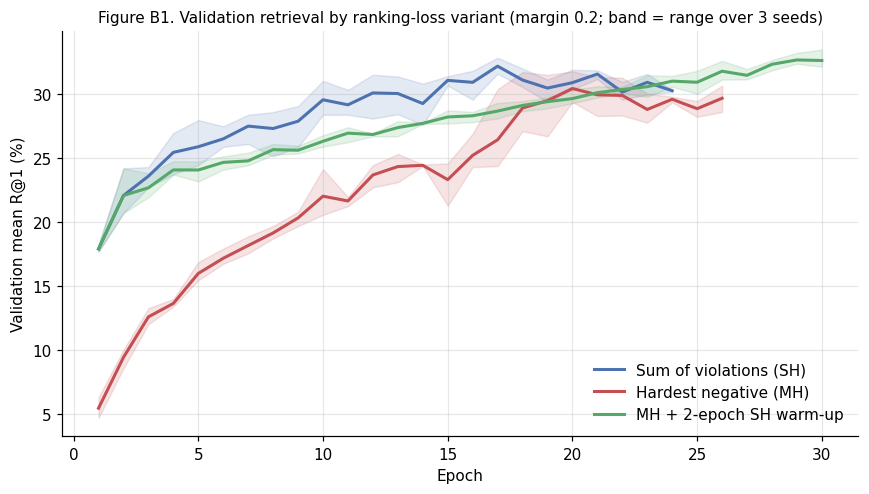

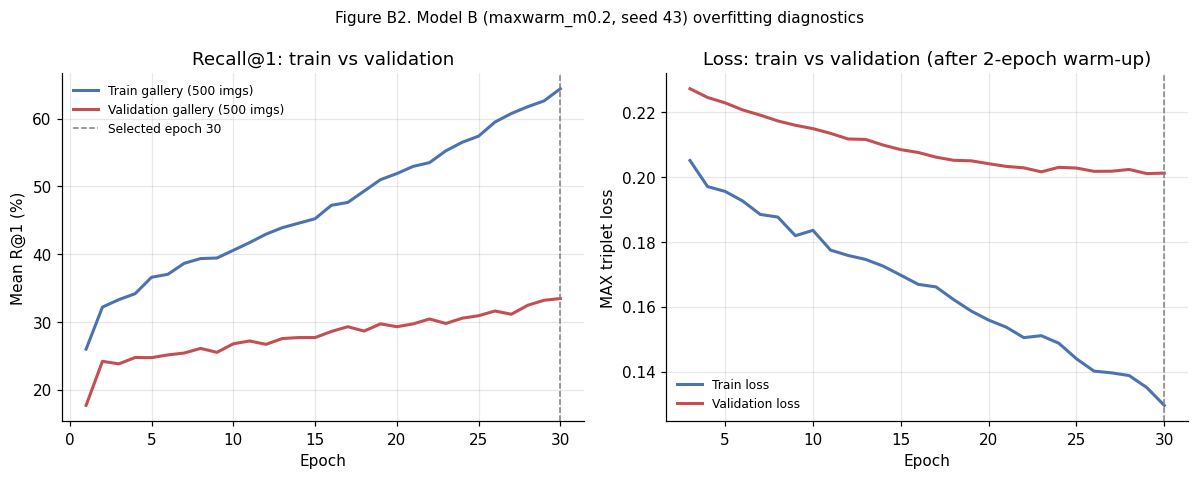

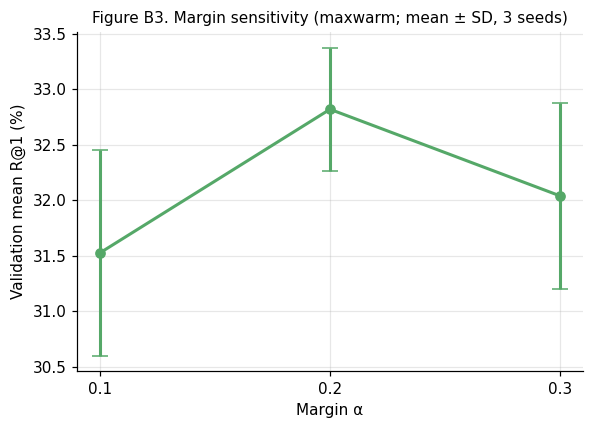

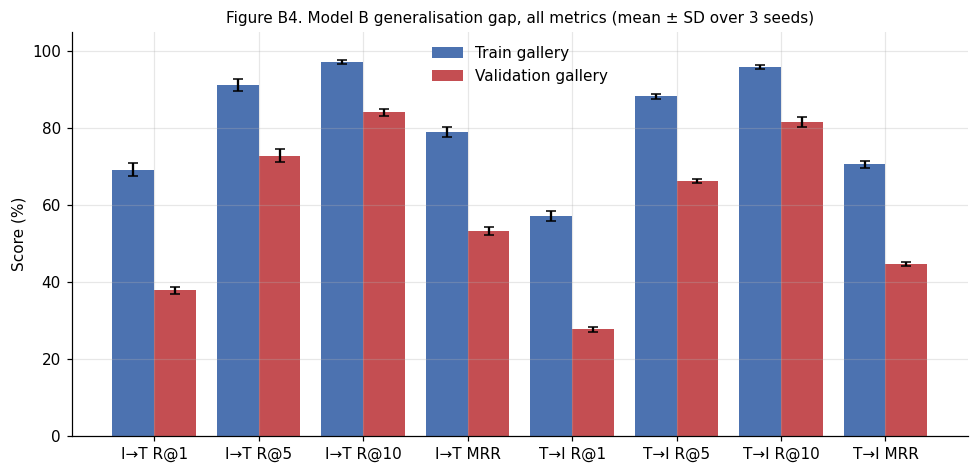

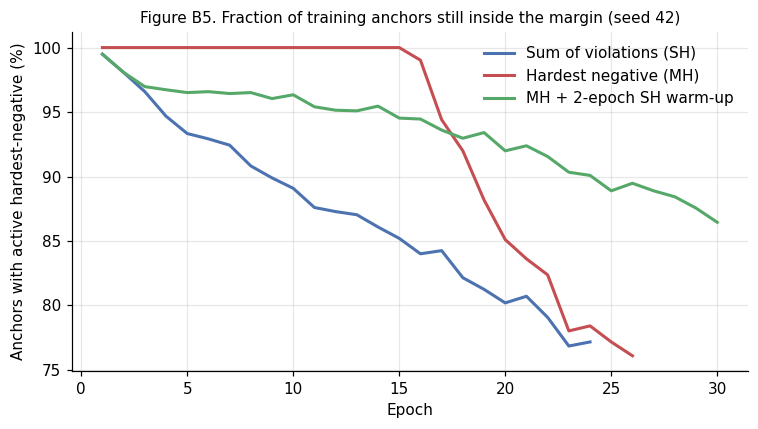

In [23]:
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"sum_m0.2": "#4C72B0", "max_m0.2": "#C44E52", "maxwarm_m0.2": "#55A868"}
LABELS = {"sum_m0.2": "Sum of violations (SH)", "max_m0.2": "Hardest negative (MH)", "maxwarm_m0.2": "MH + 2-epoch SH warm-up"}

def hist(name, seed):
    return json.loads((RESULTS / f"triplet_{name}_history_seed_{seed}.json").read_text())

# Figure B1: validation R@1 by loss variant (mean line, shaded seed range)
fig, ax = plt.subplots(figsize=(8, 4.6))
for name, *_ in LOSS_CONFIGS:
    hs = [hist(name, s) for s in RUN_SEEDS]
    L = min(len(h) for h in hs)
    y = np.array([[e["val_average_r1"] * 100 for e in h[:L]] for h in hs])
    x = np.arange(1, L + 1)
    ax.plot(x, y.mean(0), color=COLORS[name], label=LABELS[name], lw=2)
    ax.fill_between(x, y.min(0), y.max(0), color=COLORS[name], alpha=0.15)
ax.set(xlabel="Epoch", ylabel="Validation mean R@1 (%)",
       title="Figure B1. Validation retrieval by ranking-loss variant (margin 0.2; band = range over 3 seeds)")
ax.title.set_fontsize(10); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(RESULTS / "triplet_loss_variants.png", dpi=250); plt.show()

# Figure B2: overfitting curves for the final config (train-gallery vs val R@1, and losses)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
h = hist(final_name, final_best["seed"])
ep = [e["epoch"] for e in h]
ax1.plot(ep, [e["train500_average_r1"] * 100 for e in h], color="#4C72B0", lw=2, label="Train gallery (500 imgs)")
ax1.plot(ep, [e["val_average_r1"] * 100 for e in h], color="#C44E52", lw=2, label="Validation gallery (500 imgs)")
ax1.axvline(final_best["best_epoch"], color="grey", ls="--", lw=1, label=f"Selected epoch {final_best['best_epoch']}")
ax1.set(xlabel="Epoch", ylabel="Mean R@1 (%)", title="Recall@1: train vs validation")
ax1.legend(frameon=False, fontsize=8)
# Warm-up epochs use the sum loss (different scale), so only same-objective epochs are plotted.
hm = [e for e in h if e["loss_mode"] == best_mode]
ax2.plot([e["epoch"] for e in hm], [e["train_loss"] for e in hm], color="#4C72B0", lw=2, label="Train loss")
ax2.plot([e["epoch"] for e in hm], [e["val_loss"] for e in hm], color="#C44E52", lw=2, label="Validation loss")
ax2.axvline(final_best["best_epoch"], color="grey", ls="--", lw=1)
ax2.set(xlabel="Epoch", ylabel=f"{best_mode.upper()} triplet loss",
        title="Loss: train vs validation" + (f" (after {best_warmup}-epoch warm-up)" if best_warmup else ""))
ax2.legend(frameon=False, fontsize=8)
fig.suptitle(f"Figure B2. Model B ({final_name}, seed {final_best['seed']}) overfitting diagnostics", fontsize=10)
fig.tight_layout(); fig.savefig(RESULTS / "triplet_overfitting_curves.png", dpi=250); plt.show()

# Figure B3: margin sensitivity
fig, ax = plt.subplots(figsize=(5.5, 4))
ms = list(margin_rows); means = [margin_rows[m]["mean"] * 100 for m in ms]; sds = [margin_rows[m]["sd"] * 100 for m in ms]
ax.errorbar(ms, means, yerr=sds, fmt="o-", capsize=5, color="#55A868", lw=2)
ax.set(xlabel="Margin α", ylabel="Validation mean R@1 (%)", xticks=ms,
       title=f"Figure B3. Margin sensitivity ({prefix}; mean ± SD, 3 seeds)")
ax.title.set_fontsize(10)
fig.tight_layout(); fig.savefig(RESULTS / "triplet_margin_sweep.png", dpi=250); plt.show()

# Figure B4: generalisation gap across all metrics
fig, ax = plt.subplots(figsize=(9, 4.4))
keys = [f"{d}/{k}" for d in DIRS for k in METRICS]
lab = [("I→T " if k.startswith("image") else "T→I ") + k.split("/")[1] for k in keys]
x = np.arange(len(keys))
ax.bar(x - 0.2, [seed_table[k]["train_mean"] * 100 for k in keys], 0.4, yerr=[seed_table[k]["train_sd"] * 100 for k in keys],
       capsize=3, color="#4C72B0", label="Train gallery")
ax.bar(x + 0.2, [seed_table[k]["val_mean"] * 100 for k in keys], 0.4, yerr=[seed_table[k]["val_sd"] * 100 for k in keys],
       capsize=3, color="#C44E52", label="Validation gallery")
ax.set(xticks=x, xticklabels=lab, ylim=(0, 105), ylabel="Score (%)",
       title=f"Figure B4. Model B generalisation gap, all metrics (mean ± SD over 3 seeds)")
ax.title.set_fontsize(10); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(RESULTS / "triplet_generalisation_gap.png", dpi=250); plt.show()

# Figure B5: share of anchors still violating the margin (explains MH vs SH dynamics)
fig, ax = plt.subplots(figsize=(7, 4))
for name, *_ in LOSS_CONFIGS:
    hh = hist(name, RUN_SEEDS[0])
    ax.plot([e["epoch"] for e in hh], [e["active_triplet_fraction"] * 100 for e in hh], color=COLORS[name], lw=2, label=LABELS[name])
ax.set(xlabel="Epoch", ylabel="Anchors with active hardest-negative (%)",
       title="Figure B5. Fraction of training anchors still inside the margin (seed 42)")
ax.title.set_fontsize(10); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(RESULTS / "triplet_active_fraction.png", dpi=250); plt.show()

## 10. Failure cases (validation, IDs and text only; no images redistributed)

In [24]:
with torch.inference_mode():
    gi = F.normalize(best_model.image_projection(X_img[val_ids]), dim=1)
    gt = F.normalize(best_model.text_projection(X_txt[val_caption_ids]), dim=1)
    sims = gi @ gt.T
    ranked = sims.argsort(dim=1, descending=True)

examples = {"image_to_text_success": [], "image_to_text_failure": []}
for row, ii in enumerate(val_ids.tolist()):
    pc = val_caption_ids[ranked[row, 0]].item()
    gold = {caption_keys[c] for c in image_to_caption[ii]}
    bucket = "image_to_text_success" if caption_keys[pc] in gold else "image_to_text_failure"
    if len(examples[bucket]) < 8:
        examples[bucket].append({"query_image_id": image_ids[ii], "retrieved_caption": texts["captions"][pc],
                                 "reference_captions": all_records[ii]["captions"][:3],
                                 "cosine_similarity": round(float(sims[row, ranked[row, 0]]), 4)})
(RESULTS / "triplet_retrieval_examples.json").write_text(json.dumps(examples, indent=2, ensure_ascii=False))
for e in examples["image_to_text_failure"][:3]:
    print(f"Image {e['query_image_id']}: retrieved '{e['retrieved_caption']}'\n   truth e.g. '{e['reference_captions'][0]}'")

Image 215958: retrieved 'a kitchen with white appliances and brown cupboards'
   truth e.g. 'A kitchen with a counter and a table with chairs.'
Image 22552: retrieved 'A cinnamon roll with icing sitting on wax paper.'
   truth e.g. 'The browned cracked crust of a baked berry pie.'
Image 485487: retrieved 'a window with rain drops on it looking at a street light'
   truth e.g. 'A snowy, icy, empty city street and a stoplight.'


## 11. Save configuration, results and export

In [25]:
analysis = {
    "final_config": final_name, "selected_seed": final_best["seed"], "selected_epoch": final_best["best_epoch"],
    "selection_based_on": "validation mean Recall@1 across 3 seeds; test not used",
    "experiment_1_loss_variants": exp1, "experiment_2_margin_sweep": {str(k): v for k, v in margin_rows.items()},
    "all_runs": all_runs, "final_per_seed": per_seed, "final_seed_table": seed_table,
    "comparison_with_A_validation": comparison,
    "epoch_budget_check": budget_check,
    "peak_gpu_memory_gb": peak_mem,
    "total_training_seconds": float(sum(r["elapsed_train_seconds"] for r in all_runs)),
}
(RESULTS / "triplet_analysis.json").write_text(json.dumps(analysis, indent=2))

config = {
    "scope": "Model B: hard-negative triplet ranking on shared frozen features",
    "shared_split_sha256": split_sha, "seeds": RUN_SEEDS, "image_counts": [TRAIN_N, VAL_N, TEST_N],
    "architecture": "Linear 2048->256, Linear 768->256, L2-normalised (identical to Model A)",
    "batch_size": BATCH_SIZE, "learning_rate": LR, "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS, "early_stopping_patience": PATIENCE,
    "loss_variants_tested": [c[0] for c in LOSS_CONFIGS], "margin_grid": MARGIN_GRID,
    "warmup_epochs": WARMUP_EPOCHS, "final_config": final_name,
    "caption_sampling": "one caption per image per batch, random each epoch",
    "duplicate_handling": "identical caption texts masked as false negatives",
    "python_version": platform.python_version(), "torch_version": torch.__version__,
    "device": str(DEVICE), "test_untouched": True,
}
(MODELS / "triplet_config.json").write_text(json.dumps(config, indent=2))

out_zip = PROJECT / "Triplet_Model_B.zip"
files = ([MODELS / "triplet_best.pt", MODELS / "triplet_config.json"]
         + [Path(r["checkpoint"]) for r in final_runs]
         + sorted(RESULTS.glob("triplet_*.json")) + sorted(RESULTS.glob("triplet_*.png")))
with ZipFile(out_zip, "w", ZIP_DEFLATED) as z:
    for p in files:
        z.write(p, arcname=str(p.relative_to(PROJECT)))
print("Model B package:", out_zip, round(out_zip.stat().st_size / 1024**2, 2), "MB")

Model B package: /content/multimodal_project/Triplet_Model_B.zip 10.9 MB


### Outputs for the group
- `Triplet_Model_B.zip`: the final checkpoint (`triplet_best.pt`), the 3 seed checkpoints for the final configuration, all training histories, `triplet_analysis.json`, `triplet_config.json` and figures B1–B5.
- For the unified comparison, load `triplet_best.pt` into `RetrievalProjection` (same state-dictionary keys as Model A) and evaluate using the common held-out gallery.

### References
- Faghri, F., Fleet, D. J., Kiros, J. R., & Fidler, S. (2018). VSE++: Improving visual-semantic embeddings with hard negatives. *BMVC*. https://arxiv.org/abs/1707.05612
- Kiros, R., Salakhutdinov, R., & Zemel, R. S. (2014). Unifying visual-semantic embeddings with multimodal neural language models. https://arxiv.org/abs/1411.2539
- Schroff, F., Kalenichenko, D., & Philbin, J. (2015). FaceNet: A unified embedding for face recognition and clustering. *CVPR*. https://arxiv.org/abs/1503.03832

---

## 3. Early fusion (Model C)

*Source notebook: `Early_Fusion_Model_C_Member_3.ipynb`. The cells below are preserved as submitted.*

# Model C: Early Fusion Image–Text Matching
**Shared dependency:** `multimodal_shared_data.zip`

This contribution evaluates a concatenation–MLP baseline for bidirectional image–text retrieval. It includes six training runs, validation results, generalisation diagnostics, qualitative retrieval analysis and CPU runtime measurements. The common feature cache and image split were retained. The held-out test is evaluated in the shared comparison section.

The model combines frozen ResNet-50 and BERT features through separate 256-dimensional projections, L2 normalisation, feature concatenation and a nonlinear matching head. It produces one logit per image–caption pair. This is feature-level early fusion at the classifier. Its retrieval score includes the joint MLP rather than only the two projection outputs.

The baseline was evaluated over the full gallery. This makes its candidate set independent of Models A and B. The proposal's shortlist re-ranking option was not evaluated in this experiment.


In [26]:
import importlib.util, subprocess, sys
for module, package in [('torch','torch'),('numpy','numpy'),('matplotlib','matplotlib')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install',package])
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import json, shutil, hashlib, platform, os
import numpy as np
import torch
torch.set_num_threads(min(4, os.cpu_count() or 1))
import matplotlib.pyplot as plt

# Colab default: /content. Local Jupyter default: directory where the kernel was started.
WORKSPACE = Path.cwd()
PROJECT = WORKSPACE / 'multimodal_project'
DATA = PROJECT / 'shared_data'
OUT = PROJECT / 'model_c'
SHARED_ZIP = WORKSPACE / 'multimodal_shared_data.zip'
OUT.mkdir(parents=True, exist_ok=True)
RUN_SEEDS = [42,43,44]
DROPOUT_GRID = [0.0,0.2]  # small, declared validation-only experiment
MAX_EPOCHS, PATIENCE, BATCH_SIZE = 30,7,128
LR, WEIGHT_DECAY, NEGATIVES_PER_DIRECTION = 1e-3,0.01,4
PAIR_CHUNK = 8192 # maximum pairs per scoring chunk
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
REUSE_COMPLETED_RUNS = True
print('Workspace:', WORKSPACE, '\nDevice:', DEVICE, '| PyTorch:',torch.__version__)



Workspace: /content 
Device: cuda | PyTorch: 2.11.0+cu130


## 1. Model implementation
The self-contained implementation below defines the data checks, concatenation–MLP scorer, sampled-pair objective, training loop and retrieval metrics. The exported `model_c.py` provides the same scoring interface for group integration.


In [27]:
MODULE_SOURCE = r'''
"""Model C: concatenation/MLP matching on the shared frozen feature cache."""
from pathlib import Path
from collections import defaultdict
import hashlib, json, random, time, platform
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

EXPECTED_SPLIT_SHA = 'd1e46656abe237698389373485b66c7be8035b4b5feaf5f372d34dd518dad3b4'

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def sync(device):
    if torch.device(device).type == 'cuda': torch.cuda.synchronize(device)

def save_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding='utf-8')

def load_shared(data, device='cpu', expected_sha=EXPECTED_SPLIT_SHA, expected_counts=(4000,500,500)):
    data = Path(data)
    for f in ['image_features.pt','text_features.pt','coco_splits.json']:
        if not (data/f).is_file(): raise FileNotFoundError(f'Missing {data/f}. Obtain multimodal_shared_data.zip from the shared preprocessing stage.')
    split_bytes = (data/'coco_splits.json').read_bytes()
    sha = hashlib.sha256(split_bytes.replace(b'\r\n',b'\n')).hexdigest()
    if expected_sha and sha != expected_sha:
        raise ValueError('Split differs from Model B. Agree on a common split before comparing models. Do not silently bypass this check.')
    splits = json.loads(split_bytes)
    names = ['train','validation','test']
    counts = [len(splits[n]) for n in names]
    assert counts == list(expected_counts), f'Unexpected split sizes: {counts}'
    records = sum([splits[n] for n in names], [])
    image_ids = [r['id'] for r in records]
    assert len(set(image_ids)) == len(image_ids), 'Repeated image ID / split leakage'
    images = torch.load(data/'image_features.pt', map_location='cpu', weights_only=True)
    texts = torch.load(data/'text_features.pt', map_location='cpu', weights_only=True)
    assert list(images['image_ids']) == image_ids, 'Image feature order mismatch'
    xi, xt = images['features'].float(), texts['features'].float()
    assert xi.shape == (len(records),2048)
    assert xt.shape == (len(texts['captions']),768)
    assert torch.isfinite(xi).all() and torch.isfinite(xt).all(), 'Nonfinite cache features'
    cap_owner = torch.as_tensor(texts['caption_image_indices'],dtype=torch.long)
    captions = list(texts['captions'])
    assert cap_owner.shape == (len(captions),)
    assert cap_owner.min() >= 0 and cap_owner.max() < len(records)
    keys = [str(c).strip().casefold() for c in captions] # exactly Model B's convention
    assert all(keys), 'Blank caption in shared cache; clean centrally during shared data preparation'
    split_labels = sum([[n]*c for n,c in zip(names,counts)],[])
    assert len(texts['caption_splits']) == len(captions)
    assert all(texts['caption_splits'][j] == split_labels[i] for j,i in enumerate(cap_owner.tolist()))
    by_image = [[] for _ in records]
    for ci,ii in enumerate(cap_owner.tolist()): by_image[ii].append(ci)
    assert all(by_image), 'Image without captions'
    for ii,r in enumerate(records):
        assert sorted(keys[c] for c in by_image[ii]) == sorted(str(c).strip().casefold() for c in r['captions']), 'Caption mapping differs from split records'
    key_owners = defaultdict(set)
    for k,ii in zip(keys,cap_owner.tolist()): key_owners[k].add(ii)
    same_caption_cross_split = sum(len({split_labels[i] for i in owners}) > 1 for owners in key_owners.values())
    ranges = {}; offset = 0
    for name,count in zip(names,counts):
        ids = torch.arange(offset,offset+count)
        cs = torch.where((cap_owner>=offset)&(cap_owner<offset+count))[0]
        ranges[name]=(ids,cs); offset += count
    train500 = torch.randperm(counts[0],generator=torch.Generator().manual_seed(42))[:min(500,counts[0])]
    ranges['train500']=(train500,torch.where(torch.isin(cap_owner,train500))[0])
    return dict(xi=xi.to(device),xt=xt.to(device),owner=cap_owner,keys=keys,captions=captions,
                by_image=by_image,key_owners=dict(key_owners),image_ids=image_ids,records=records,
                ranges=ranges,sha=sha,counts=counts,device=str(device),
                audit={'caption_count':len(captions),'duplicate_texts_crossing_splits':same_caption_cross_split,
                       'note':'Image-disjoint splits; repeated caption text across splits is reported, not silently removed.'})

class EarlyFusionMLP(nn.Module):
    """Feature-level concatenation, then nonlinear pair scoring; not a dual encoder."""
    def __init__(self,image_dim=2048,text_dim=768,projection_dim=256,hidden_dim=256,dropout=0.2):
        super().__init__()
        self.config=dict(image_dim=image_dim,text_dim=text_dim,projection_dim=projection_dim,hidden_dim=hidden_dim,dropout=dropout)
        self.image_projection=nn.Linear(image_dim,projection_dim)
        self.text_projection=nn.Linear(text_dim,projection_dim)
        self.matcher=nn.Sequential(nn.Linear(2*projection_dim,hidden_dim),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden_dim,1))
    def encode_images(self,x): return F.normalize(self.image_projection(x),dim=-1)
    def encode_texts(self,x): return F.normalize(self.text_projection(x),dim=-1)
    def score_encoded(self,a,b): return self.matcher(torch.cat((a,b),dim=-1)).squeeze(-1)
    def forward(self,xi,xt): return self.score_encoded(self.encode_images(xi),self.encode_texts(xt))

@torch.inference_mode()
def score_matrix(model,xi,xt,pair_chunk=8192):
    """Exact full-gallery concatenation/MLP logits, factored for efficient inference.

    W[a;b]+bias = W_image*a + W_text*b + bias. Only the pairwise
    addition, ReLU and output layer scale with the gallery product.
    Dropout is disabled by eval(), so this is the SAME trained matcher,
    not an approximation, shortlist, or a replacement similarity model.
    """
    assert pair_chunk > 0 and len(xi)>0 and len(xt)>0
    model.eval()
    a,b=model.encode_images(xi),model.encode_texts(xt)
    first,last=model.matcher[0],model.matcher[3]
    k=a.shape[1]
    ai=F.linear(a,first.weight[:,:k],first.bias)
    bt=F.linear(b,first.weight[:,k:],None)
    out=torch.empty((len(a),len(b)),dtype=torch.float32,device='cpu')
    flat=out.view(-1)
    for start in range(0,out.numel(),pair_chunk):
        idx=torch.arange(start,min(start+pair_chunk,out.numel()),device=a.device)
        h=F.relu(ai[idx//len(b)]+bt[idx%len(b)])
        vals=last(h).squeeze(-1)
        flat[start:start+len(vals)]=vals.float().cpu()
    return out

def pair_logits(model,d,ii,cc):
    # Reuse projections of repeated IDs within a labelled minibatch; gradients
    # still accumulate exactly as when every repeated pair is projected alone.
    ui,inv_i=torch.unique(ii,return_inverse=True)
    uc,inv_c=torch.unique(cc,return_inverse=True)
    a=model.encode_images(d['xi'][ui]); b=model.encode_texts(d['xt'][uc])
    return model.score_encoded(a[inv_i],b[inv_c])

def correctness(d,ids,cs,duplicate_aware=True):
    ids,cs=torch.as_tensor(ids).cpu(),torch.as_tensor(cs).cpu()
    truth=ids[:,None].eq(d['owner'][cs][None,:])
    if duplicate_aware:
        local=defaultdict(set)
        for ci in cs.tolist(): local[d['keys'][ci]].add(int(d['owner'][ci]))
        for col,ci in enumerate(cs.tolist()):
            owners=local[d['keys'][ci]]
            if len(owners)>1: truth[:,col] |= torch.tensor([i in owners for i in ids.tolist()])
    return truth

def first_ranks(scores,truth):
    assert scores.shape==truth.shape and truth.any(1).all(), 'Every query needs a valid candidate'
    # Stable tie ordering is deterministic; report it in the protocol.
    hits=truth.gather(1,scores.argsort(dim=1,descending=True,stable=True))
    return hits.to(torch.int64).argmax(1)+1

def recall_mrr(scores,truth):
    ranks=first_ranks(scores,truth)
    return {**{f'R@{k}':float((ranks<=k).float().mean()) for k in [1,5,10]},'MRR':float((1/ranks.float()).mean())}

def metrics_from_scores(d,scores,ids,cs):
    out={}
    for name,aware in [('ambiguous_aware',True),('strict_origin',False)]:
        truth=correctness(d,ids,cs,aware)
        out[name]={'image_to_text':recall_mrr(scores,truth),'text_to_image':recall_mrr(scores.T,truth.T)}
    return out

def evaluate(model,d,split='validation',pair_chunk=8192):
    ids,cs=d['ranges'][split]
    s=score_matrix(model,d['xi'][ids.to(d['xi'].device)],d['xt'][cs.to(d['xt'].device)],pair_chunk)
    return metrics_from_scores(d,s,ids,cs)

def avg_r1(metrics):
    m=metrics['ambiguous_aware']
    return (m['image_to_text']['R@1']+m['text_to_image']['R@1'])/2

def sampled_pairs(d,ids,rng,negatives=4):
    """One positive caption/image; equal numbers of both negative directions.
    Excludes all matching owners and captions whose normalized text is valid for the image.
    Negative candidates come ONLY from ids (training or validation, never mixed).
    """
    ids=[int(i) for i in ids]
    positive_caps=[rng.choice(d['by_image'][i]) for i in ids]
    ii=list(ids); cc=list(positive_caps); yy=[1.]*len(ids)
    for i,c in zip(ids,positive_caps):
        valid_images=[j for j in ids if j not in d['key_owners'][d['keys'][c]]]
        if not valid_images: continue
        for _ in range(negatives):
            # Wrong caption for this image: choose a different owner and reject ambiguous text.
            for _attempt in range(100):
                j=rng.choice(ids); nc=rng.choice(d['by_image'][j])
                if i not in d['key_owners'][d['keys'][nc]]: break
            else: continue
            ii.append(i);cc.append(nc);yy.append(0.)
            # Wrong image for this caption.
            ii.append(rng.choice(valid_images));cc.append(c);yy.append(0.)
    return torch.tensor(ii),torch.tensor(cc),torch.tensor(yy)

def balanced_bce(logits,labels):
    # Positive and negative classes each receive half of the objective, independent of ratio.
    pos=labels.bool(); neg=~pos
    assert pos.any() and neg.any(), 'Need both positive and valid negative pairs'
    losses=F.binary_cross_entropy_with_logits(logits,labels,reduction='none')
    return .5*(losses[pos].mean()+losses[neg].mean())

@torch.inference_mode()
def pair_loss(model,d,pairs,chunk=4096):
    model.eval(); ii,cc,y=pairs; device=d['xi'].device
    sums=[0.,0.];counts=[0,0]
    for st in range(0,len(y),chunk):
        ix,tx,labels=ii[st:st+chunk].to(device),cc[st:st+chunk].to(device),y[st:st+chunk].to(device)
        losses=F.binary_cross_entropy_with_logits(pair_logits(model,d,ix,tx),labels,reduction='none')
        for cls in [0,1]:
            mask=labels.eq(cls);sums[cls]+=float(losses[mask].sum());counts[cls]+=int(mask.sum())
    assert min(counts)>0
    return .5*sum(s/n for s,n in zip(sums,counts))

def train_run(d,out,seed=42,dropout=.2,epochs=30,patience=7,batch_size=128,lr=.001,weight_decay=.01,negatives=4,pair_chunk=8192,diagnostic_every=5):
    out=Path(out);(out/'models').mkdir(parents=True,exist_ok=True);(out/'results').mkdir(exist_ok=True)
    set_seed(seed); rng=random.Random(seed);device=d['xi'].device
    model=EarlyFusionMLP(dropout=dropout).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=weight_decay)
    name=f'concat_dropout{dropout:g}_seed{seed}'; path=out/'models'/f'fusion_{name}_best.pt'
    trids=d['ranges']['train'][0].tolist(); vaids=d['ranges']['validation'][0].tolist()
    fixed_val=sampled_pairs(d,vaids,random.Random(2026),negatives)
    fixed_train=sampled_pairs(d,d['ranges']['train500'][0].tolist(),random.Random(2026),negatives)
    best=-1.; no_gain=0;history=[];train_seconds=0.
    if device.type=='cuda': torch.cuda.reset_peak_memory_stats(device)
    sync(device); started=time.perf_counter()
    for ep in range(1,epochs+1):
        model.train();order=torch.randperm(len(trids)).tolist()
        weighted_loss=0.;seen=0;sync(device);ts=time.perf_counter()
        for st in range(0,len(order),batch_size):
            ids=[trids[k] for k in order[st:st+batch_size]]
            if len(ids)<2: continue
            ix,cx,labels=sampled_pairs(d,ids,rng,negatives)
            ix,cx,labels=ix.to(device),cx.to(device),labels.to(device)
            logits=pair_logits(model,d,ix,cx);loss=balanced_bce(logits,labels)
            opt.zero_grad(set_to_none=True);loss.backward();opt.step()
            weighted_loss+=float(loss.detach())*len(ids);seen+=len(ids)
        sync(device);elapsed=time.perf_counter()-ts;train_seconds+=elapsed
        val=evaluate(model,d,'validation',pair_chunk);score=avg_r1(val)
        row={'epoch':ep,'train_loss':weighted_loss/seen,'fixed_train_loss':pair_loss(model,d,fixed_train),
             'val_loss':pair_loss(model,d,fixed_val),'val_average_r1':score,
             'val_i2t_r1':val['ambiguous_aware']['image_to_text']['R@1'],
             'val_t2i_r1':val['ambiguous_aware']['text_to_image']['R@1'],'train_step_seconds':elapsed}
        if ep==1 or ep%diagnostic_every==0: row['train500_average_r1']=avg_r1(evaluate(model,d,'train500',pair_chunk))
        history.append(row)
        if score>best+1e-6:
            best=score;no_gain=0
            torch.save({'model_state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
                        'model_config':model.config,'seed':seed,'best_epoch':ep,'validation_avg_r1':score,
                        'shared_split_sha256':d['sha'],'scoring':'full_gallery_pairwise_logits','test_untouched':True},path)
        else: no_gain+=1
        save_json(out/'results'/f'fusion_{name}_history.json',history)
        print(f'{name} epoch {ep:02}: loss {row["train_loss"]:.4f}; validation mean R@1 {score:.2%}',flush=True)
        if no_gain>=patience:break
    sync(device)
    run={'seed':seed,'dropout':dropout,'checkpoint':str(path),'best_val_average_r1':best,
         'epochs_run':len(history),'train_step_seconds':train_seconds,'total_run_seconds':time.perf_counter()-started,
         'parameter_count':sum(p.numel() for p in model.parameters()),
         'peak_pytorch_allocated_gb':torch.cuda.max_memory_allocated(device)/1024**3 if device.type=='cuda' else None,
         'history':history}
    save_json(out/'results'/f'fusion_{name}_run.json',run)
    return run

def load_model(checkpoint,device='cpu',expected_sha=None):
    cp=torch.load(checkpoint,map_location='cpu',weights_only=True)
    if expected_sha and cp['shared_split_sha256']!=expected_sha:raise ValueError('Checkpoint split mismatch')
    model=EarlyFusionMLP(**cp['model_config']).to(device)
    model.load_state_dict(cp['model_state_dict']);model.eval()
    return model,cp

def runtime_benchmark(model,d,split='validation',pair_chunk=8192,repeats=3):
    ids,cs=d['ranges'][split];device=d['xi'].device
    xi,xt=d['xi'][ids.to(device)],d['xt'][cs.to(device)]
    score_matrix(model,xi[:1],xt[:min(20,len(xt))],pair_chunk) # warm-up, excluded
    times=[]
    for _ in range(repeats):
        sync(device);start=time.perf_counter();scores=score_matrix(model,xi,xt,pair_chunk);sync(device)
        times.append(time.perf_counter()-start)
    # Separately measure ranking and metrics (CPU), not mixed with model throughput.
    t=time.perf_counter();metrics_from_scores(d,scores,ids,cs);metrics_sec=time.perf_counter()-t
    return {'split':split,'images':len(ids),'captions':len(cs),'pairs':scores.numel(),'repeats_seconds':times,
            'median_gallery_scoring_seconds':float(np.median(times)),'pairs_per_second':scores.numel()/float(np.median(times)),
            'ranking_and_metrics_seconds':metrics_sec,'pair_chunk':pair_chunk,'device':str(device),
            'gpu':torch.cuda.get_device_name(device) if device.type=='cuda' else None,
            'timing_scope':'cached features -> projected features -> all pair logits -> CPU score matrix; excludes encoder extraction, disk I/O and ranking',
            'note':'One matrix supports both retrieval directions. Amortised gallery time is not isolated online query latency.'}

def retrieval_examples(model,d,split='validation',limit=8,pair_chunk=8192):
    ids,cs=d['ranges'][split];dev=d['xi'].device
    scores=score_matrix(model,d['xi'][ids.to(dev)],d['xt'][cs.to(dev)],pair_chunk)
    truth=correctness(d,ids,cs,True);out={}
    for direction,s,t in [('image_to_text',scores,truth),('text_to_image',scores.T,truth.T)]:
        order=s.argsort(dim=1,descending=True,stable=True);ranks=first_ranks(s,t)
        for success in [False,True]:
            bucket=[]
            for q in torch.where((ranks==1)==success)[0].tolist()[:limit]:
                candidates=[]
                for j in order[q,:5].tolist():
                    if direction=='image_to_text':item={'caption':d['captions'][int(cs[j])],'caption_index':int(cs[j])}
                    else:
                        ii=int(ids[j]);item={'image_id':d['image_ids'][ii],'reference_captions':[d['captions'][c] for c in d['by_image'][ii]][:3]}
                    candidates.append({**item,'matching_logit':float(s[q,j]),'correct_duplicate_aware':bool(t[q,j])})
                if direction=='image_to_text':
                    ii=int(ids[q]);query={'image_id':d['image_ids'][ii],'reference_captions':[d['captions'][c] for c in d['by_image'][ii]]}
                else:query={'caption':d['captions'][int(cs[q])],'reference_image_id':d['image_ids'][int(d['owner'][cs[q]])]}
                bucket.append({'query':query,'first_correct_rank':int(ranks[q]),'top5':candidates,
                               'retrieval_status':('accepted_reference_match' if success else 'reference_mismatch')})
            out[direction+('_success' if success else '_failure')]=bucket
    return out
'''
MODULE_PATH = OUT / 'model_c.py'
MODULE_PATH.write_text(MODULE_SOURCE, encoding='utf-8')
import importlib.util
spec = importlib.util.spec_from_file_location('group11_model_c', MODULE_PATH)
mc = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mc)
print('Model C implementation:', MODULE_PATH)


Model C implementation: /content/multimodal_project/model_c/model_c.py


## 2. Shared data and validation protocol
The cache contains 4,000 training images, 500 validation images and 500 test images, with 25,010 captions in total. The validation gallery contains 500 images and all 2,499 associated captions. Image IDs and caption ownership were checked against the shared split, whose SHA-256 matches the group configuration.

The audit records 57 normalised caption texts that occur across image-disjoint splits. The split was preserved to keep the experiments comparable; repeated text remains a limitation of the data. Duplicate-aware primary metrics and strict-origin secondary metrics are retained.

Test rows are present in the supplied cache, but the training, model-selection and diagnostic routines below select training or validation rows only.


In [28]:
required = ['image_features.pt','text_features.pt','coco_splits.json']
if not all((DATA/f).is_file() for f in required):
    if not SHARED_ZIP.is_file():
        raise FileNotFoundError(f'Missing shared feature archive: {SHARED_ZIP}')
    # Extract only the required files; reject ambiguous archive layouts.
    with ZipFile(SHARED_ZIP) as z:
        DATA.mkdir(parents=True, exist_ok=True)
        for filename in required:
            matches = [i for i in z.infolist() if not i.is_dir() and Path(i.filename).name==filename]
            if len(matches)!=1:
                raise ValueError(f'Expected exactly one {filename}; found {len(matches)}. Archive layout is ambiguous.')
            with z.open(matches[0]) as src, (DATA/filename).open('wb') as dst:
                shutil.copyfileobj(src,dst)
d = mc.load_shared(DATA, DEVICE)
print('Images train/validation/test:',d['counts'])
print('Split SHA-256:',d['sha'])
print('Cache audit:',json.dumps(d['audit'],indent=2))
print('Model C parameters:',sum(p.numel() for p in mc.EarlyFusionMLP().parameters()))



Images train/validation/test: [4000, 500, 500]
Split SHA-256: d1e46656abe237698389373485b66c7be8035b4b5feaf5f372d34dd518dad3b4
Cache audit: {
  "caption_count": 25010,
  "duplicate_texts_crossing_splits": 57,
  "note": "Image-disjoint splits; repeated caption text across splits is reported, not silently removed."
}
Model C parameters: 852993


## 3. Training design and configuration selection
The experiment compared dropout 0.0 and 0.2 using seeds 42, 43 and 44. Both configurations used AdamW, learning rate 0.001, weight decay 0.01, batches of 128 images, a 30-epoch cap and early stopping after seven epochs without improved validation mean Recall@1.

Each minibatch sampled one positive caption per image and up to four negative captions and four negative images per positive pair. Correct owners and identical normalised caption matches were excluded from negatives. The objective assigned equal weight to mean positive and mean negative binary cross-entropy.

The common frozen features, split and nominal training settings support comparison with the other models. Model C changes both architecture and objective and processes more labelled pairs per image batch, so equal epoch caps do not imply equal computation.

Dropout 0.2 achieved a mean directional validation Recall@1 of **5.21% ± 0.68 percentage points**, compared with **4.87% ± 1.17 percentage points** for dropout 0.0. The selected configuration therefore uses dropout 0.2. These are three-seed summaries, not a statistical significance test.


In [29]:
protocol = {
    'shared_split_sha256':d['sha'], 'seeds':RUN_SEEDS,'dropout_grid':DROPOUT_GRID,
    'max_epochs':MAX_EPOCHS,'patience':PATIENCE,'batch_size_images':BATCH_SIZE,
    'lr':LR,'weight_decay':WEIGHT_DECAY,'negatives_per_direction':NEGATIVES_PER_DIRECTION,
    'pair_chunk':PAIR_CHUNK,'projection_dim':256,'hidden_dim':256,
    'gallery':'full; 500 images vs all associated captions','test_untouched':True,
    'python':platform.python_version(),'torch':str(torch.__version__),'numpy':np.__version__,
    'device':str(DEVICE), 'cpu_threads':torch.get_num_threads(), 'platform':platform.platform(), 'module_sha256':hashlib.sha256(MODULE_SOURCE.encode()).hexdigest(),
    'objective':'0.5 * (mean positive BCE + mean negative BCE)',
    'caveat':'A/B versus C changes architecture and objective; equal epochs do not imply equal compute.'
}
protocol_sha = hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
mc.save_json(OUT/'results'/'fusion_protocol.json',protocol)
all_runs=[]
for dropout in DROPOUT_GRID:
    for seed in RUN_SEEDS:
        name=f'concat_dropout{dropout:g}_seed{seed}'
        cache=OUT/'results'/f'fusion_{name}_completed.json'
        if REUSE_COMPLETED_RUNS and cache.is_file():
            saved=json.loads(cache.read_text())
            if saved.get('protocol_sha256')==protocol_sha and Path(saved['run']['checkpoint']).is_file():
                r=saved['run'];print('Reusing completed run:',name)
            else: raise ValueError('Cached run protocol differs. Set REUSE_COMPLETED_RUNS=False to deliberately retrain.')
        else:
            r=mc.train_run(d,OUT,seed=seed,dropout=dropout,epochs=MAX_EPOCHS,patience=PATIENCE,
                           batch_size=BATCH_SIZE,lr=LR,weight_decay=WEIGHT_DECAY,
                           negatives=NEGATIVES_PER_DIRECTION,pair_chunk=PAIR_CHUNK)
            mc.save_json(cache,{'protocol_sha256':protocol_sha,'run':r})
        all_runs.append(r)
summary={str(p):{'mean':float(np.mean([r['best_val_average_r1'] for r in all_runs if r['dropout']==p])),
                       'sd':float(np.std([r['best_val_average_r1'] for r in all_runs if r['dropout']==p],ddof=1))}
         for p in DROPOUT_GRID}
selected_dropout=max(DROPOUT_GRID,key=lambda p:summary[str(p)]['mean'])
print('Validation mean R@1 across directions and seeds:',json.dumps(summary,indent=2))
print('Selected dropout:',selected_dropout)


concat_dropout0_seed42 epoch 01: loss 0.6270; validation mean R@1 1.92%
concat_dropout0_seed42 epoch 02: loss 0.4572; validation mean R@1 1.46%
concat_dropout0_seed42 epoch 03: loss 0.3766; validation mean R@1 2.36%
concat_dropout0_seed42 epoch 04: loss 0.3421; validation mean R@1 3.30%
concat_dropout0_seed42 epoch 05: loss 0.3107; validation mean R@1 3.86%
concat_dropout0_seed42 epoch 06: loss 0.2894; validation mean R@1 3.58%
concat_dropout0_seed42 epoch 07: loss 0.2653; validation mean R@1 4.54%
concat_dropout0_seed42 epoch 08: loss 0.2572; validation mean R@1 3.40%
concat_dropout0_seed42 epoch 09: loss 0.2424; validation mean R@1 5.38%
concat_dropout0_seed42 epoch 10: loss 0.2376; validation mean R@1 4.98%
concat_dropout0_seed42 epoch 11: loss 0.2327; validation mean R@1 4.86%
concat_dropout0_seed42 epoch 12: loss 0.2301; validation mean R@1 4.26%
concat_dropout0_seed42 epoch 13: loss 0.2145; validation mean R@1 4.14%
concat_dropout0_seed42 epoch 14: loss 0.2189; validation mean R@

## 4. Validation results
Results are reported as mean ± sample standard deviation across all three seeds of the selected configuration. Values are percentages; the standard deviations are in percentage points. The canonical integration checkpoint uses the fixed seed 42. The three seed checkpoints are retained for the group's final evaluation.

| Direction | Recall@1 | Recall@5 | Recall@10 | MRR |
|---|---:|---:|---:|---:|
| Image → text | 5.67% ± 0.83 | 20.67% ± 1.81 | 33.33% ± 3.23 | 14.43% ± 1.43 |
| Text → image | 4.76% ± 0.83 | 20.38% ± 2.74 | 35.24% ± 3.88 | 14.43% ± 1.77 |

Recall@K records whether any accepted candidate appears in the first K positions; MRR uses the first accepted candidate's rank. Duplicate-aware matching follows the shared normalisation convention. Strict-origin results are available in `fusion_validation_metrics.json`.

The baseline does not meet the proposal's targets of at least 10% Recall@1 and 25% Recall@5 in both directions. The measurements establish the performance of this particular full-gallery concatenation–MLP configuration; they do not establish a general limitation of early fusion.


In [30]:
final_runs=[r for r in all_runs if r['dropout']==selected_dropout]
seed_results=[]
for r in final_runs:
    model,cp=mc.load_model(r['checkpoint'],DEVICE,d['sha'])
    vm=mc.evaluate(model,d,'validation',PAIR_CHUNK)
    tm=mc.evaluate(model,d,'train500',PAIR_CHUNK)
    seed_results.append({'seed':r['seed'],'best_epoch':cp['best_epoch'],'validation':vm,'train500':tm})
metric_summary={}
for protocol_name in ['ambiguous_aware','strict_origin']:
    metric_summary[protocol_name]={}
    for direction in ['image_to_text','text_to_image']:
        metric_summary[protocol_name][direction]={}
        for metric in ['R@1','R@5','R@10','MRR']:
            vals=[r['validation'][protocol_name][direction][metric] for r in seed_results]
            metric_summary[protocol_name][direction][metric]={'mean':float(np.mean(vals)),'sd':float(np.std(vals,ddof=1))}
for direction,vals in metric_summary['ambiguous_aware'].items():
    print(direction)
    for metric,v in vals.items():print(f'  {metric}: {v["mean"]:.2%} ± {v["sd"]:.2%}')
canonical=next(r for r in final_runs if r['seed']==42)
shutil.copyfile(canonical['checkpoint'],OUT/'models'/'fusion_best.pt')
model,checkpoint=mc.load_model(OUT/'models'/'fusion_best.pt',DEVICE,d['sha'])
mc.save_json(OUT/'results'/'fusion_validation_metrics.json',{'summary':metric_summary,'per_seed':seed_results})


image_to_text
  R@1: 5.53% ± 0.23%
  R@5: 21.87% ± 2.04%
  R@10: 35.60% ± 1.25%
  MRR: 15.25% ± 0.82%
text_to_image
  R@1: 5.42% ± 0.40%
  R@5: 21.13% ± 0.35%
  R@10: 35.77% ± 1.52%
  MRR: 15.17% ± 0.31%


## 5. Generalisation and training behaviour
At the selected checkpoints, mean directional Recall@1 is **5.77%** on the fixed 500-image training gallery and **5.21%** on validation, a difference of **0.55 percentage points**. The gap varies by seed: seed 42's validation result slightly exceeds its training-gallery result, while seeds 43 and 44 show positive training–validation gaps. This does not support a claim of severe, consistent overfitting across every seed.

Training loss decreases more consistently than full-gallery retrieval improves. This is compatible with both limited generalisation and a mismatch between sampled binary pair classification and the retrieval-ranking objective; the experiment does not isolate either as a sole cause.

The figures show validation retrieval each epoch and training-gallery retrieval every five epochs. Fixed-sample training and validation BCE provide a comparable loss diagnostic. Both retrieval galleries contain 500 images and all their associated captions.


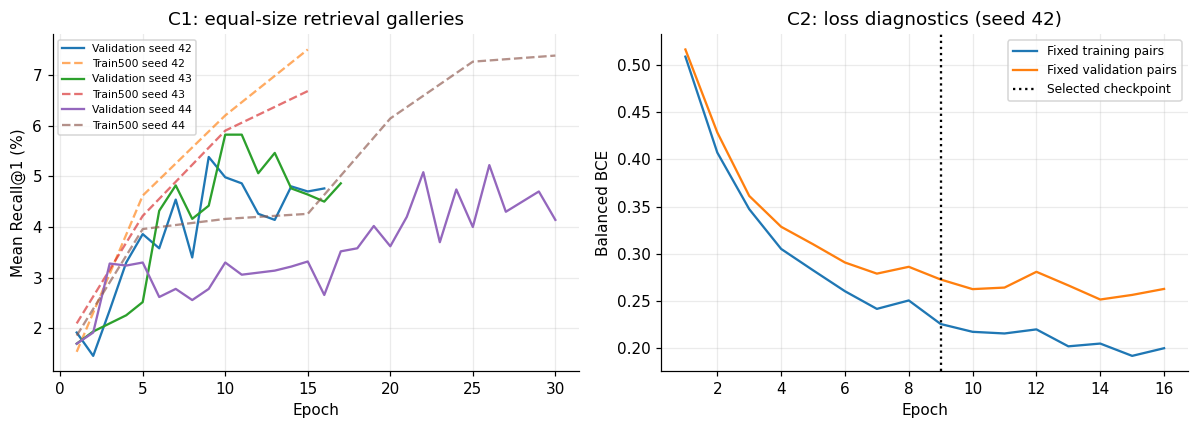

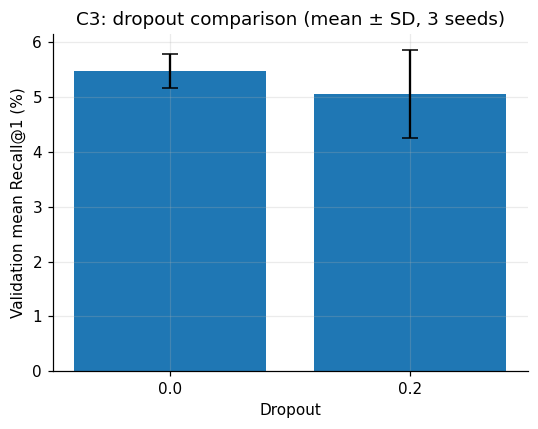

In [31]:
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.25})
fig,(a,b)=plt.subplots(1,2,figsize=(11,4))
for r in final_runs:
    h=r['history']; ep=[x['epoch'] for x in h]
    a.plot(ep,[x['val_average_r1']*100 for x in h],label=f'Validation seed {r["seed"]}')
    hh=[x for x in h if 'train500_average_r1' in x]
    a.plot([x['epoch'] for x in hh],[x['train500_average_r1']*100 for x in hh],ls='--',alpha=.65,label=f'Train500 seed {r["seed"]}')
a.set(xlabel='Epoch',ylabel='Mean Recall@1 (%)',title='C1: equal-size retrieval galleries');a.legend(fontsize=7)
h=canonical['history'];ep=[x['epoch'] for x in h]
b.plot(ep,[x['fixed_train_loss'] for x in h],label='Fixed training pairs')
b.plot(ep,[x['val_loss'] for x in h],label='Fixed validation pairs')
b.axvline(checkpoint['best_epoch'],ls=':',color='black',label='Selected checkpoint')
b.set(xlabel='Epoch',ylabel='Balanced BCE',title='C2: loss diagnostics (seed 42)');b.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'results'/'fusion_overfitting.png',dpi=200);plt.show()
fig,ax=plt.subplots(figsize=(5,4))
ax.bar([str(p) for p in DROPOUT_GRID],[summary[str(p)]['mean']*100 for p in DROPOUT_GRID],
       yerr=[summary[str(p)]['sd']*100 for p in DROPOUT_GRID],capsize=5)
ax.set(xlabel='Dropout',ylabel='Validation mean Recall@1 (%)',title='C3: dropout comparison (mean ± SD, 3 seeds)')
fig.tight_layout();fig.savefig(OUT/'results'/'fusion_dropout_comparison.png',dpi=200);plt.show()


## 6. Retrieval failure analysis
The qualitative review covers eight failures in each direction and eight successful examples in each direction. Each record retains the query, top-five candidates, matching logits and first accepted rank. The observations compare retrieved text with the available reference captions; original images were not included in the reviewed files.

Three recurring patterns appear in the selected examples:

- **Broad scene similarity with incorrect detail.** Kitchen queries retrieve other kitchen scenes without establishing the requested furniture or sink relationship. A bus example preserves the vehicle and street context but changes the stated colour and scene details.
- **Object or food-category substitution.** Pie references retrieve doughnut or pizza descriptions, and a restroom example ranks a teacup-clock caption first. The latter has an accepted caption at rank 2, whereas other failures place the first accepted candidate much farther down the ranking.
- **Annotation ambiguity.** One beach example contains tennis, baseball and badminton labels across its references. Its failure cannot be interpreted as an unambiguous visual classification error from caption text alone.

The examples are selected in fixed gallery order and are illustrative rather than a representative estimate of error-category frequency. The completed observations are stored in `fusion_failure_review.json` for the group's qualitative comparison.


In [32]:
REVIEW_NOTES = {
  "[\"image_to_text_failure\", {\"image_id\": 215958, \"reference_captions\": [\"A kitchen with a counter and a table with chairs.\", \"A large dining room features wooden cabinets and a marble counter top.\", \"a black counter a sink and a table and two chairs\", \"A kitchen island has a farmhouse sink on it.\", \"A sink in a peninsula in a kitchen.\"]}, \"A living room with a fireplace and glass slider doors.\"]": {
    "error_category": "Room-category confusion",
    "analysis": "The reference captions describe kitchen counters, a sink and dining furniture, whereas the top-ranked caption describes a living room with a fireplace and sliding doors. The retrieved text shares a broad indoor setting but differs in the annotated room and objects."
  },
  "[\"image_to_text_failure\", {\"image_id\": 22552, \"reference_captions\": [\"The browned cracked crust of a baked berry pie.\", \"A brown crust of pie with strawberry filing.\", \"The top of a pie looks all crusty and good.\", \"A close up of a cooked fruit flavored muffin.\", \"An image of some sort of strawberry flaky pastery on display\"]}, \"A dozen doughnuts sits in a doughnut box and two are chocolate, three are glazed and one is a raised pink iced.\"]": {
    "error_category": "Baked-food subtype confusion",
    "analysis": "The references mainly describe a berry pie or pastry, with one referring to a muffin. The top caption describes a box of doughnuts. Both belong to a broad baked-food category, but the retrieved subtype is not accepted by the reference mapping. Variation among the reference labels limits a more precise diagnosis."
  },
  "[\"image_to_text_failure\", {\"image_id\": 485487, \"reference_captions\": [\"A snowy, icy, empty city street and a stoplight.\", \"A cleared crosswalk in a city on a snowy, slushy day\", \"A city street that has piles on snow on it\", \"The road in the city is quiet and empty.\", \"A city with snow and slush filling the ground.\"]}, \"A sleek white, red and blue motorcycle parked opposite of several others.\"]": {
    "error_category": "Street-scene and vehicle confusion",
    "analysis": "The references emphasize a snowy street, crosswalk and stoplight, while the top caption describes parked motorcycles. The first accepted caption is sixth: this example misses Recall@5 but is recovered at Recall@10."
  },
  "[\"image_to_text_failure\", {\"image_id\": 175726, \"reference_captions\": [\"a toilet with writing under the lid\", \"Handicapped restroom with open toilet and black and white spotted floor.\", \"A bathroom with a soap dispenser, toilet and rolls of toilet paper.\", \"There are two rolls of toilet paper and a hand dispenser on the bathroom wall.\", \"A toilet in a small room with a two-roll dispenser for toilet paper.\"]}, \"A clock that has replaced numbers with teacups\"]": {
    "error_category": "Object-category mismatch",
    "analysis": "The reference captions describe a toilet and restroom fittings; the retrieved caption describes a clock with teacups. An accepted caption appears second, so the failure concerns the top-ranked candidate rather than the absence of a correct candidate near the top."
  },
  "[\"image_to_text_failure\", {\"image_id\": 103531, \"reference_captions\": [\"Some chairs sit at an island near an open door.\", \"A kitchen in a house under construction and painting.\", \"A kitchen featuring an open island for seating with high back stools.\", \"In an unfinished room a counter sits with three chairs while a stove and cabinets sit in the distance.\", \"a kitchen with a stove a table some chairs and a sink\"]}, \"This desk has a desk top computer along with pictures and a lamp\"]": {
    "error_category": "Indoor-furniture context confusion",
    "analysis": "The references describe an island, stools and kitchen fittings in an unfinished room. The top caption instead describes a computer desk, pictures and a lamp. The accepted caption is far down the ranking, indicating a substantial failure to preserve the annotated room context."
  },
  "[\"image_to_text_failure\", {\"image_id\": 486072, \"reference_captions\": [\"A woman holding a tennis racquet in the air\", \"Two women at a beach with tennis rackets in their hands and one girl looking very excited with her tennis racket in the air.\", \"A woman holding a baseball bat over her head on the sand.\", \"A few friends going to the beach playing badminton.\", \"A group of people standing on top of a beach.\"]}, \"A uniformed baseball player being watched by people.\"]": {
    "error_category": "Sports context and reference ambiguity",
    "analysis": "The references contain several sport labels, including tennis, baseball and badminton, together with a beach setting. The top caption describes a uniformed baseball player. The retrieved wording overlaps one reference term, but it does not resolve the conflicting reference descriptions or preserve the common beach context. This case cannot support a definite visual-error diagnosis."
  },
  "[\"image_to_text_failure\", {\"image_id\": 392557, \"reference_captions\": [\"A white bus is driving down the street\", \"VERY BLURRY PHOTO OF A BUS SPEEDING THROUGH A TUNNEL\", \"A city bus driving on a road with blurred lights and the city street behind it.\", \"A bus driving down a street at night.\", \"A bus driving down the road really fast\"]}, \"A green bus with people driving on a city street.\"]": {
    "error_category": "Semantically related scene with attribute mismatch",
    "analysis": "Both the reference and retrieved captions describe a bus on a city street. The references mention a white bus, night and motion blur, whereas the top caption specifies a green bus with people. This illustrates the difference between broad semantic similarity and an accepted annotation-level match."
  },
  "[\"image_to_text_failure\", {\"image_id\": 402597, \"reference_captions\": [\"A man riding on the back of a brown horse.\", \"Two people ride matching cream-colored horses at a gas station.\", \"Two men are riding on horses at a gas station.\", \"two young men on horseback at a gas station near some gas pumps and trucks\", \"a teenager on a horse at a gas station.\"]}, \"A skater rides along a steep red wall.\"]": {
    "error_category": "Shared action with different object and setting",
    "analysis": "The references describe people riding horses at a gas station, while the retrieved caption describes a skater on a red wall. A broad riding action is shared, but the annotated object and location differ."
  },
  "[\"text_to_image_failure\", {\"caption\": \"A kitchen with a counter and a table with chairs.\", \"reference_image_id\": 215958}, 755449]": {
    "error_category": "Generic kitchen-scene ambiguity",
    "analysis": "The query specifies a kitchen with a counter, table and chairs. The top image references establish a cramped, cluttered kitchen but do not establish the requested furniture relationships. This is a same-scene-category mismatch under the reference mapping; the alternative image has not been visually verified."
  },
  "[\"text_to_image_failure\", {\"caption\": \"A large dining room features wooden cabinets and a marble counter top.\", \"reference_image_id\": 215958}, 755449]": {
    "error_category": "Missing discriminating attributes",
    "analysis": "The query specifies wooden cabinets and a marble countertop. The top image references describe a cramped kitchen without establishing those attributes. The caption evidence is consistent with coarse scene matching but does not support the distinguishing details in the query."
  },
  "[\"text_to_image_failure\", {\"caption\": \"a black counter a sink and a table and two chairs\", \"reference_image_id\": 215958}, 321762]": {
    "error_category": "Shared object with conflicting room context",
    "analysis": "The query combines a sink with a black counter, table and chairs. The top image references describe a bathroom sink with toothbrushes. The shared sink term is insufficient to preserve the query context and object relationships."
  },
  "[\"text_to_image_failure\", {\"caption\": \"A kitchen island has a farmhouse sink on it.\", \"reference_image_id\": 215958}, 507679]": {
    "error_category": "Kitchen context without the requested relationship",
    "analysis": "The query describes a farmhouse sink on a kitchen island. The top image references emphasize a refrigerator in a kitchen corner. The broad kitchen context is retained, but the requested sink-island relationship is not supported by the available references. The accepted image is third."
  },
  "[\"text_to_image_failure\", {\"caption\": \"A sink in a peninsula in a kitchen.\", \"reference_image_id\": 215958}, 103531]": {
    "error_category": "Kitchen-island ambiguity",
    "analysis": "The query concerns a sink in a kitchen peninsula. The top image references describe a kitchen island and stools without establishing the sink. This is a related scene whose suitability cannot be confirmed from the reference text alone."
  },
  "[\"text_to_image_failure\", {\"caption\": \"The browned cracked crust of a baked berry pie.\", \"reference_image_id\": 22552}, 314044]": {
    "error_category": "Pie versus pizza confusion",
    "analysis": "The query describes the browned, cracked crust of a berry pie. The top image references describe a frozen pizza in an oven. The texts share baked-food context, but the food subtype differs and the accepted image is ranked 43rd."
  },
  "[\"text_to_image_failure\", {\"caption\": \"A brown crust of pie with strawberry filing.\", \"reference_image_id\": 22552}, 445793]": {
    "error_category": "Food subtype and attribute mismatch",
    "analysis": "The query describes a brown pie crust with strawberry filling. The top image references describe food in a foam container, including rice. General food context does not establish the requested pastry, crust or fruit filling. The accepted image is ranked 30th."
  },
  "[\"text_to_image_failure\", {\"caption\": \"The top of a pie looks all crusty and good.\", \"reference_image_id\": 22552}, 816759]": {
    "error_category": "Broad baked-food wording",
    "analysis": "The query describes a pie and its crust, while the top image references describe pizza. Both texts concern baked food, but the requested subtype is not preserved. The accepted image is sixth, just outside Recall@5."
  }
}

def annotate_examples(records, notes):
    reviewed = json.loads(json.dumps(records))
    for direction, entries in reviewed.items():
        for entry in entries:
            entry.pop('manual_error_category', None)
            entry.pop('manual_explanation', None)
            top = entry['top5'][0]
            signature = json.dumps([direction, entry['query'], top.get('caption', top.get('image_id'))],
                                   sort_keys=True, ensure_ascii=False)
            if direction.endswith('_success'):
                observation = {'error_category':'Accepted reference match',
                               'analysis':'The top-ranked candidate is accepted by the duplicate-aware reference mapping. This establishes retrieval success under the stated protocol rather than independent visual correctness.'}
            else:
                observation = notes.get(signature, {
                    'error_category':'Reference-mapping mismatch',
                    'analysis':f"The top-ranked candidate is outside the accepted reference mapping. The first accepted candidate has rank {entry['first_correct_rank']}; no candidate-specific semantic interpretation is assigned to this changed retrieval."})
            entry.update(observation)
            entry['assessment_basis'] = 'Retrieved text and reference captions; original images were not inspected.'
    return reviewed

examples = mc.retrieval_examples(model, d, 'validation', limit=8, pair_chunk=PAIR_CHUNK)
reviewed_examples = annotate_examples(examples, REVIEW_NOTES)
mc.save_json(OUT/'results'/'fusion_retrieval_examples.json', examples)
mc.save_json(OUT/'results'/'fusion_failure_review.json', reviewed_examples)
for direction in ['image_to_text_failure', 'text_to_image_failure']:
    print('\n' + direction)
    for entry in reviewed_examples[direction][:3]:
        print(f"First accepted rank {entry['first_correct_rank']}: {entry['error_category']}")
        print(entry['analysis'])



image_to_text_failure
First accepted rank 2: Reference-mapping mismatch
The top-ranked candidate is outside the accepted reference mapping. The first accepted candidate has rank 2; no candidate-specific semantic interpretation is assigned to this changed retrieval.
First accepted rank 3: Reference-mapping mismatch
The top-ranked candidate is outside the accepted reference mapping. The first accepted candidate has rank 3; no candidate-specific semantic interpretation is assigned to this changed retrieval.
First accepted rank 60: Reference-mapping mismatch
The top-ranked candidate is outside the accepted reference mapping. The first accepted candidate has rank 60; no candidate-specific semantic interpretation is assigned to this changed retrieval.

text_to_image_failure
First accepted rank 14: Reference-mapping mismatch
The top-ranked candidate is outside the accepted reference mapping. The first accepted candidate has rank 14; no candidate-specific semantic interpretation is assigned t

In [33]:
review_path = OUT / "results" / "fusion_failure_review.json"
review_data = json.loads(review_path.read_text())

for direction, entries in review_data.items():
    for entry in entries:
        category = entry.get("error_category", "")
        rank = entry["first_correct_rank"]

        if category == "Street-scene and vehicle confusion":
            observation = (
                "The reference captions describe a snowy street, crosswalk "
                "and stoplight, while the top caption describes parked motorcycles."
            )
        elif category == "Broad baked-food wording":
            observation = (
                "The query describes a pie and its crust, while the retrieved "
                "image references describe pizza. The requested food subtype "
                "is not preserved."
            )
        else:
            continue

        outcome = (
            "The example succeeds at Recall@5."
            if rank <= 5
            else "The example fails at Recall@5."
        )
        entry["analysis"] = (
            f"{observation} The first accepted candidate is at rank {rank}. "
            f"{outcome}"
        )
        print(category, "→", entry["analysis"])

mc.save_json(review_path, review_data)

Broad baked-food wording → The query describes a pie and its crust, while the retrieved image references describe pizza. The requested food subtype is not preserved. The first accepted candidate is at rank 4. The example succeeds at Recall@5.


## 7. Runtime and computational implications
The measured median full-gallery scoring time is **1.489 seconds** over three CPU repeats after warm-up. The gallery contains **1,249,500 image–caption pairs**. Ranking and metric calculation take **0.578 seconds** separately. Frozen-feature extraction, file loading and disk I/O are outside this scoring measurement.

Across all six runs, the recorded training-step time totals **212.91 seconds**; the total run time including epoch diagnostics is **536.02 seconds**. These CPU measurements are specific to the recorded environment and are not directly comparable with another member's GPU training times.

Inference factors the first concatenation layer as `W_image·image + W_text·text + bias` before applying the same ReLU and output layer. This preserves the MLP score while avoiding repeated first-layer matrix multiplication for every pair. Pairwise activation work still grows with the image–caption gallery product. The model therefore has different scaling characteristics from a cosine-based dual encoder.


In [34]:
runtime=mc.runtime_benchmark(model,d,'validation',PAIR_CHUNK,repeats=3)
mc.save_json(OUT/'results'/'fusion_runtime.json',runtime)
print(json.dumps(runtime,indent=2))
print('Total pure training-step seconds across all experiments:',sum(r['train_step_seconds'] for r in all_runs))
print('Total run seconds including epoch diagnostics:',sum(r['total_run_seconds'] for r in all_runs))


{
  "split": "validation",
  "images": 500,
  "captions": 2499,
  "pairs": 1249500,
  "repeats_seconds": [
    0.07334001300000637,
    0.07366398999988633,
    0.07489165700008016
  ],
  "median_gallery_scoring_seconds": 0.07366398999988633,
  "pairs_per_second": 16962154.77877221,
  "ranking_and_metrics_seconds": 0.3349338089999492,
  "pair_chunk": 8192,
  "device": "cuda:0",
  "gpu": "Tesla T4",
  "timing_scope": "cached features -> projected features -> all pair logits -> CPU score matrix; excludes encoder extraction, disk I/O and ranking",
  "note": "One matrix supports both retrieval directions. Amortised gallery time is not isolated online query latency."
}
Total pure training-step seconds across all experiments: 29.67675824699927
Total run seconds including epoch diagnostics: 91.51819432000048


## 8. Group integration and exported artefacts
The export contains the selected configuration, canonical seed-42 checkpoint, all three selected-configuration seed checkpoints, histories, validation metrics, figures, runtime results and completed qualitative observations. Numerical experiment records and trained weights are preserved from the recorded run.

For the unified comparison, the model interface returns a matrix with image rows and caption columns, with larger logits indicating stronger matches. `member4_evaluation_example.py` demonstrates the shared-cache and checkpoint interfaces. Final test evaluation belongs to the group comparison after model choices are fixed; no final test result is reported here.


In [35]:
analysis={'selected_dropout':selected_dropout,'configuration_selection':'mean validation average R@1 over 3 seeds',
          'canonical_seed':42,'split_sha256':d['sha'],'dropout_experiment':summary,'runs':all_runs,
          'validation_summary':metric_summary,'runtime':runtime,'test_untouched':True}
mc.save_json(OUT/'results'/'fusion_analysis.json',analysis)
comparison_example = "# Integrated model comparison: run after placing model_c.py on your import path.\nimport torch\nimport model_c as mc\ndevice = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\nd = mc.load_shared('multimodal_project/shared_data', device)\nmodel, checkpoint = mc.load_model('models/fusion_best.pt', device, d['sha'])\n# Final test evaluation belongs here, after all model settings are frozen:\nids, caps = d['ranges']['test']\nscores = mc.score_matrix(model, d['xi'][ids.to(device)], d['xt'][caps.to(device)])\n# scores: rows = image queries, columns = caption candidates; larger is better.\n# Prefer your shared metric code; this adapter also provides both conventions:\nmetrics = mc.metrics_from_scores(d, scores, ids, caps)\nprint(metrics)\n# Repeat for each selected seed checkpoint and report mean +/- sample SD.\n"
(OUT/'model_comparison_example.py').write_text(comparison_example,encoding='utf-8')
mc.save_json(OUT/'models'/'fusion_config.json', {**protocol, 'selected_dropout':selected_dropout, 'canonical_seed':42})
package=WORKSPACE/'Early_Fusion_Model_C.zip'
with ZipFile(package,'w',ZIP_DEFLATED) as z:
    selected_paths=[OUT/'models'/'fusion_config.json',OUT/'models'/'fusion_best.pt']+[Path(r['checkpoint']) for r in final_runs]
    selected_paths+=list((OUT/'results').glob('fusion_*'))+[MODULE_PATH,OUT/'model_comparison_example.py']
    for p in dict.fromkeys(selected_paths):
        if p.is_file():z.write(p,arcname=str(p.relative_to(OUT)))
print('Model C artefact:', package)
print('Contents: checkpoints, configuration, validation results, figures, runtime and qualitative review.')


Model C artefact: /content/Early_Fusion_Model_C.zip
Contents: checkpoints, configuration, validation results, figures, runtime and qualitative review.


## Contribution summary for the group
Model C provides an independently evaluated full-gallery early-fusion baseline using the common cache and split. Dropout 0.2 was selected on validation, but its seed-averaged retrieval scores remain below the proposal targets. The contribution includes evidence for the final comparison: all retrieval metrics, seed variability, loss and recall curves, candidate-level examples and measured CPU scoring cost.

The next group deliverable is the shared test comparison across the retained seed checkpoints. The qualitative examples support discussion of scene similarity, object substitution and annotation ambiguity alongside the project's broader bias assessment.



---

## 4. Unified evaluation of Models A, B, and C

*Source notebook: `Model_Comparison_Member_4.ipynb`. The cells below are preserved as submitted.*

### Archive path compatibility for integrated comparison

Earlier sections save the shared dataset, InfoNCE, and Triplet ZIPs inside `multimodal_project/`, while the comparison code expects those ZIP files next to the notebook. This **one additional bridge cell only copies the generated archives** to that expected location; model-training code is not modified.

In [36]:
from pathlib import Path
import shutil

workspace = Path.cwd()
project_dir = workspace / "multimodal_project"
archive_sources = {
    "multimodal_shared_data.zip": project_dir / "multimodal_shared_data.zip",
    "InfoNCE_Model_A.zip": project_dir / "InfoNCE_Model_A.zip",
    "Triplet_Model_B.zip": project_dir / "Triplet_Model_B.zip",
    "Early_Fusion_Model_C.zip": WORKSPACE / "Early_Fusion_Model_C.zip",
}
for name, source in archive_sources.items():
    destination = workspace / name
    if not source.is_file():
        raise FileNotFoundError(f"Expected archive from preceding section: {source}")
    if source.resolve() != destination.resolve():
        shutil.copy2(source, destination)
print("All four generated archives are available for the integrated comparison.")

All four generated archives are available for the integrated comparison.


## Environment and Setup

In [37]:
import importlib.util, subprocess, sys
for module, package in [("torch", "torch"), ("numpy", "numpy"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

from pathlib import Path
from collections import defaultdict
from zipfile import ZipFile, ZIP_DEFLATED
import json, time, hashlib, platform, shutil
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

PROJECT = Path.cwd() / "multimodal_project"
DATA, MODELS, RESULTS = PROJECT / "shared_data", PROJECT / "models", PROJECT / "results"
for d in (DATA, MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)


for zip_name in ["multimodal_shared_data.zip", "InfoNCE_Model_A.zip", "Triplet_Model_B.zip", "Early_Fusion_Model_C.zip"]:
    zpath = Path.cwd() / zip_name
    assert zpath.exists(), f"Place {zip_name} in the same folder as this notebook"
    with ZipFile(zpath, "r") as z:
        for member in z.infolist():
            if member.is_dir():
                continue
            fname = Path(member.filename).name
            if fname in ("coco_splits.json", "image_features.pt", "text_features.pt"):
                target = DATA / fname
            elif fname.endswith(".pt") or fname.endswith("_config.json"):
                target = MODELS / fname
            elif fname.endswith(".py"):
                target = PROJECT / fname
            else:
                target = RESULTS / fname
            with z.open(member) as src, target.open("wb") as dst:
                shutil.copyfileobj(src, dst)

SPLIT_SEED = 42
RUN_SEEDS = [42, 43, 44]
TRAIN_N, VAL_N, TEST_N = 4000, 500, 500
EMBED_DIM = 256
PAIR_CHUNK = 8192

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch", torch.__version__)

Device: cuda | torch 2.11.0+cu130


## Load Shared Splits and Frozen Features

In [38]:
images = torch.load(DATA / "image_features.pt", map_location="cpu", weights_only=True)
texts = torch.load(DATA / "text_features.pt", map_location="cpu", weights_only=True)
with (DATA / "coco_splits.json").open(encoding="utf-8") as f:
    splits = json.load(f)

all_records = splits["train"] + splits["validation"] + splits["test"]
image_ids = [r["id"] for r in all_records]
assert images["image_ids"] == image_ids, "Image feature order does not match the shared split"
assert images["features"].shape == (5000, 2048)
assert texts["features"].shape == (len(texts["captions"]), 768)

cap_img = texts["caption_image_indices"]
assert all(texts["caption_splits"][j] == ("train" if i < 4000 else "validation" if i < 4500 else "test")
           for j, i in enumerate(cap_img)), "A caption crosses a split boundary"

X_img = images["features"].float().to(DEVICE)
X_txt = texts["features"].float().to(DEVICE)
caption_to_image = torch.tensor(cap_img, dtype=torch.long, device=DEVICE)
caption_keys = [str(c).strip().casefold() for c in texts["captions"]]

image_to_caption = [[] for _ in range(5000)]
for ci, ii in enumerate(cap_img):
    image_to_caption[ii].append(ci)

# Fixed 500 image galleries for train500, validation, and held out test
train_500 = torch.randperm(TRAIN_N, generator=torch.Generator().manual_seed(SPLIT_SEED))[:500].to(DEVICE)
train_500_captions = torch.where(torch.isin(caption_to_image, train_500))[0]

val_ids = torch.arange(4000, 4500, device=DEVICE)
val_caption_ids = torch.where((caption_to_image >= 4000) & (caption_to_image < 4500))[0]

test_ids = torch.arange(4500, 5000, device=DEVICE)
test_caption_ids = torch.where((caption_to_image >= 4500) & (caption_to_image < 5000))[0]

split_sha = hashlib.sha256((DATA / "coco_splits.json").read_bytes().replace(b"\r\n", b"\n")).hexdigest()
print("Split SHA-256:", split_sha)
print(f"Galleries -> Train500: {len(train_500)} imgs ({len(train_500_captions)} caps) | "
      f"Val: {len(val_ids)} imgs ({len(val_caption_ids)} caps) | "
      f"Test: {len(test_ids)} imgs ({len(test_caption_ids)} caps)")

Split SHA-256: d1e46656abe237698389373485b66c7be8035b4b5feaf5f372d34dd518dad3b4
Galleries -> Train500: 500 imgs (2500 caps) | Val: 500 imgs (2499 caps) | Test: 500 imgs (2503 caps)


## Common Model Architectures and Evaluation Code

In [39]:
class RetrievalProjection(nn.Module):
    # Shared architecture for Model A (InfoNCE) and Model B (Triplet Ranking)
    def __init__(self, dimension=EMBED_DIM):
        super().__init__()
        self.image_projection = nn.Linear(2048, dimension)
        self.text_projection = nn.Linear(768, dimension)

    def forward(self, x_image, x_text):
        return (F.normalize(self.image_projection(x_image), dim=-1),
                F.normalize(self.text_projection(x_text), dim=-1))


class EarlyFusionMLP(nn.Module):
    # Architecture for Model C (Concatenation + MLP Matcher)
    def __init__(self, image_dim=2048, text_dim=768, projection_dim=256, hidden_dim=256, dropout=0.2):
        super().__init__()
        self.image_projection = nn.Linear(image_dim, projection_dim)
        self.text_projection = nn.Linear(text_dim, projection_dim)
        self.matcher = nn.Sequential(
            nn.Linear(2 * projection_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def encode_images(self, x):
        return F.normalize(self.image_projection(x), dim=-1)

    def encode_texts(self, x):
        return F.normalize(self.text_projection(x), dim=-1)


@torch.inference_mode()
def score_matrix_mlp(model, xi, xt, pair_chunk=PAIR_CHUNK):
    # Pranav's exact factored MLP scoring for Model C
    model.eval()
    a, b = model.encode_images(xi), model.encode_texts(xt)
    first, last = model.matcher[0], model.matcher[3]
    k = a.shape[1]
    ai = F.linear(a, first.weight[:, :k], first.bias)
    bt = F.linear(b, first.weight[:, k:], None)
    out = torch.empty((len(a), len(b)), dtype=torch.float32, device=DEVICE)
    flat = out.view(-1)
    for start in range(0, out.numel(), pair_chunk):
        idx = torch.arange(start, min(start + pair_chunk, out.numel()), device=DEVICE)
        h = F.relu(ai[idx // len(b)] + bt[idx % len(b)])
        flat[start : start + len(h)] = last(h).squeeze(-1).float()
    return out


def recall_mrr(similarity, correct):
    # True if ANY valid caption/image occurs in top k, returns R@1, R@5, R@10, and MRR
    order = similarity.argsort(dim=1, descending=True, stable=True)
    hits = correct.gather(1, order)
    assert hits.any(dim=1).all(), "Some retrieval queries have no eligible correct result"
    first = hits.to(torch.int32).argmax(dim=1) + 1
    return {f"R@{k}": float((first <= k).float().mean()) for k in (1, 5, 10)} | {
        "MRR": float((1.0 / first.float()).mean())
    }


def retrieval_metrics(model, gallery_images, gallery_captions, include_strict=True):
    # Unified retrieval protocol for Models A, B, and C
    model.eval()
    with torch.inference_mode():
        if isinstance(model, RetrievalProjection):
            a, b = model(X_img[gallery_images], X_txt[gallery_captions])
            sims = a @ b.T
        else:
            sims = score_matrix_mlp(model, X_img[gallery_images], X_txt[gallery_captions])

        truth = gallery_images[:, None].eq(caption_to_image[gallery_captions][None, :])
        strict = {
            "image_to_text": recall_mrr(sims, truth),
            "text_to_image": recall_mrr(sims.T, truth.T),
        }

        # accept any gallery image sharing identical caption text
        ambiguous = truth.clone()
        owner_by_key = defaultdict(set)
        for ii, ci in zip(caption_to_image[gallery_captions].tolist(), gallery_captions.tolist()):
            owner_by_key[caption_keys[ci]].add(ii)
        gids = gallery_images.tolist()
        for col, ci in enumerate(gallery_captions.tolist()):
            owners = owner_by_key[caption_keys[ci]]
            if len(owners) > 1:
                ambiguous[:, col] |= torch.tensor([g in owners for g in gids], dtype=torch.bool, device=DEVICE)

        broad = {
            "image_to_text": recall_mrr(sims, ambiguous),
            "text_to_image": recall_mrr(sims.T, ambiguous.T),
        }
    out = {"ambiguous_aware": broad}
    if include_strict:
        out["strict_origin"] = strict
    return out

print("Common evaluation functions ready.")

Common evaluation functions ready.


## Evaluate Models A, B, and C Across Seeds (Validation & Test)

In [40]:
def load_model_ab(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = RetrievalProjection().to(DEVICE)
    m.load_state_dict(ck["model_state_dict"])
    m.eval()
    return m, ck

def load_model_c(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = EarlyFusionMLP(**ck["model_config"]).to(DEVICE)
    m.load_state_dict(ck["model_state_dict"])
    m.eval()
    return m, ck

# Load the validation-selected configurations from the preceding training sections.
triplet_selected = json.loads((MODELS / "triplet_config.json").read_text())["final_config"]
fusion_selected = json.loads((MODELS / "fusion_config.json").read_text())["selected_dropout"]
fusion_dropout_label = f"{float(fusion_selected):g}"

MODEL_PATHS = {
    "Model A (InfoNCE)": ([MODELS / f"infonce_seed_{s}_best.pt" for s in RUN_SEEDS], load_model_ab),
    "Model B (Triplet)": ([MODELS / f"triplet_{triplet_selected}_seed_{s}_best.pt" for s in RUN_SEEDS], load_model_ab),
    "Model C (Early Fusion)": ([MODELS / f"fusion_concat_dropout{fusion_dropout_label}_seed{s}_best.pt" for s in RUN_SEEDS], load_model_c),
}

METRICS = ("R@1", "R@5", "R@10", "MRR")
DIRS = ("image_to_text", "text_to_image")

all_model_results = {}
runtime_benchmarks = {}

for model_name, (paths, loader) in MODEL_PATHS.items():
    per_seed = []
    for p in paths:
        m, ck = loader(p)
        per_seed.append({
            "seed": ck["seed"],
            "best_epoch": ck["best_epoch"],
            "train_500": retrieval_metrics(m, train_500, train_500_captions),
            "validation_500": retrieval_metrics(m, val_ids, val_caption_ids),
            "test_500": retrieval_metrics(m, test_ids, test_caption_ids),
        })
    all_model_results[model_name] = per_seed

    # Benchmark full-gallery scoring time on the 500-image test split (3 repeats)
    m, _ = loader(paths[0])
    times = []
    for _ in range(3):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.inference_mode():
            if isinstance(m, RetrievalProjection):
                a, b = m(X_img[test_ids], X_txt[test_caption_ids])
                _ = a @ b.T
            else:
                _ = score_matrix_mlp(m, X_img[test_ids], X_txt[test_caption_ids])
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    runtime_benchmarks[model_name] = float(np.median(times))

def agg(per_seed, gallery, proto, d, k):
    vals = [s[gallery][proto][d][k] for s in per_seed]
    return float(np.mean(vals)), float(np.std(vals, ddof=1))

for split_key, split_label in [("validation_500", "VALIDATION (500 IMGS)"), ("test_500", "HELD-OUT TEST (500 IMGS)")]:
    print(f"\n= {split_label} — Mean ± SD over seeds {RUN_SEEDS}")
    for d in DIRS:
        print(f"\n {d}")
        print(f"  {'Model':<24} {'R@1':<18} {'R@5':<18} {'R@10':<18} {'MRR':<18}")
        for model_name, per_seed in all_model_results.items():
            row_str = f"  {model_name:<24}"
            for k in METRICS:
                mean_v, sd_v = agg(per_seed, split_key, "ambiguous_aware", d, k)
                row_str += f" {mean_v*100:5.2f}% ± {sd_v*100:4.2f}%   "
            print(row_str)

print("\n TEST GALLERY SCORING RUNTIME")
for model_name, med_sec in runtime_benchmarks.items():
    print(f"  {model_name:<24}: median scoring time = {med_sec*1000:.2f} ms")


= VALIDATION (500 IMGS) — Mean ± SD over seeds [42, 43, 44]

 image_to_text
  Model                    R@1                R@5                R@10               MRR               
  Model A (InfoNCE)        37.33% ± 1.27%    71.60% ± 1.91%    84.20% ± 1.00%    52.31% ± 0.35%   
  Model B (Triplet)        37.87% ± 0.90%    72.93% ± 1.70%    84.20% ± 0.87%    53.27% ± 1.05%   
  Model C (Early Fusion)    5.53% ± 0.23%    21.87% ± 2.04%    35.60% ± 1.25%    15.25% ± 0.82%   

 text_to_image
  Model                    R@1                R@5                R@10               MRR               
  Model A (InfoNCE)        27.30% ± 0.89%    65.75% ± 1.72%    81.62% ± 1.39%    44.05% ± 1.06%   
  Model B (Triplet)        27.77% ± 0.70%    66.40% ± 0.49%    81.66% ± 1.32%    44.72% ± 0.58%   
  Model C (Early Fusion)    5.42% ± 0.40%    21.13% ± 0.35%    35.77% ± 1.52%    15.17% ± 0.31%   

= HELD-OUT TEST (500 IMGS) — Mean ± SD over seeds [42, 43, 44]

 image_to_text
  Model                    

## Generate Comparison Graphs

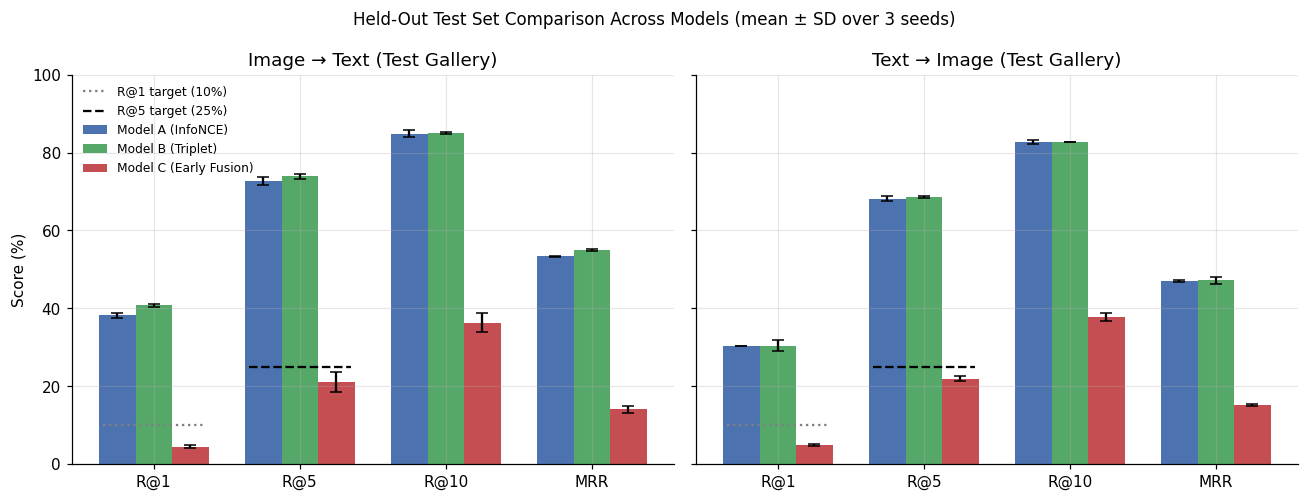

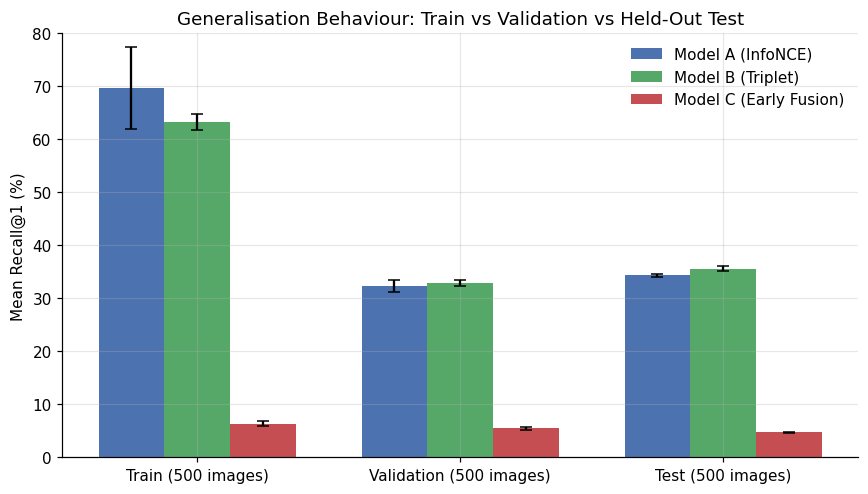

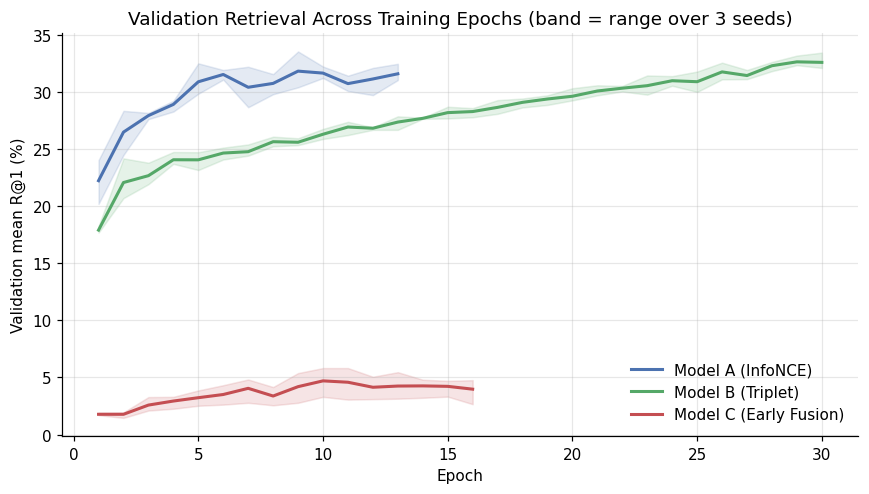

Saved comparison figures to: /content/multimodal_project/results


In [41]:
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {
    "Model A (InfoNCE)": "#4C72B0",
    "Model B (Triplet)": "#55A868",
    "Model C (Early Fusion)": "#C44E52",
}

# Held Out Test Set Performance Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
x = np.arange(len(METRICS))
width = 0.25

for ax, d, title in [(ax1, "image_to_text", "Image → Text (Test Gallery)"),
                     (ax2, "text_to_image", "Text → Image (Test Gallery)")]:
    for i, (model_name, per_seed) in enumerate(all_model_results.items()):
        means = [agg(per_seed, "test_500", "ambiguous_aware", d, k)[0] * 100 for k in METRICS]
        sds = [agg(per_seed, "test_500", "ambiguous_aware", d, k)[1] * 100 for k in METRICS]
        ax.bar(x + (i - 1) * width, means, width=width, yerr=sds, capsize=4,
               color=COLORS[model_name], label=model_name)
    # Target guides apply only to their corresponding metric, not every bar group.
    ax.hlines(10, -0.35, 0.35, color="grey", linestyles=":", lw=1.5, label="R@1 target (10%)")
    ax.hlines(25, 0.65, 1.35, color="black", linestyles="--", lw=1.5, label="R@5 target (25%)")
    ax.set(xticks=x, xticklabels=METRICS, ylim=(0, 100), title=title)
    if d == "image_to_text":
        ax.set_ylabel("Score (%)")
        ax.legend(frameon=False, fontsize=8)

fig.suptitle("Held-Out Test Set Comparison Across Models (mean ± SD over 3 seeds)", fontsize=11)
fig.tight_layout()
fig.savefig(RESULTS / "comparison_test_metrics.png", dpi=250)
plt.show()

# Generalisation Gap Across Train500, Validation, and Test (Mean R@1)
fig, ax = plt.subplots(figsize=(8, 4.6))
galleries = ["train_500", "validation_500", "test_500"]
gal_labels = ["Train (500 images)", "Validation (500 images)", "Test (500 images)"]
x_g = np.arange(len(galleries))

for i, (model_name, per_seed) in enumerate(all_model_results.items()):
    means, sds = [], []
    for g in galleries:
        vals = [0.5 * (s[g]["ambiguous_aware"]["image_to_text"]["R@1"] +
                       s[g]["ambiguous_aware"]["text_to_image"]["R@1"]) * 100 for s in per_seed]
        means.append(np.mean(vals))
        sds.append(np.std(vals, ddof=1))
    ax.bar(x_g + (i - 1) * width, means, width=width, yerr=sds, capsize=4,
           color=COLORS[model_name], label=model_name)

ax.set(xticks=x_g, xticklabels=gal_labels, ylim=(0, 80),
       ylabel="Mean Recall@1 (%)", title="Generalisation Behaviour: Train vs Validation vs Held-Out Test")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "comparison_generalisation_gap.png", dpi=250)
plt.show()

# Validation Recall@1 Curves Across Epochs (Using Saved History JSONs)
fig, ax = plt.subplots(figsize=(8, 4.6))
hist_files = [
    ("Model A (InfoNCE)", "infonce_history_seed_{}.json"),
    ("Model B (Triplet)", f"triplet_{triplet_selected}_history_seed_{{}}.json"),
    ("Model C (Early Fusion)", f"fusion_concat_dropout{fusion_dropout_label}_seed{{}}_history.json"),
]

for model_name, pattern in hist_files:
    hs = [json.loads((RESULTS / pattern.format(s)).read_text()) for s in RUN_SEEDS]
    L = min(len(h) for h in hs)
    y = np.array([[e["val_average_r1"] * 100 for e in h[:L]] for h in hs])
    ep = np.arange(1, L + 1)
    ax.plot(ep, y.mean(0), color=COLORS[model_name], lw=2, label=model_name)
    ax.fill_between(ep, y.min(0), y.max(0), color=COLORS[model_name], alpha=0.15)

ax.set(xlabel="Epoch", ylabel="Validation mean R@1 (%)",
       title="Validation Retrieval Across Training Epochs (band = range over 3 seeds)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "comparison_validation_curves.png", dpi=250)
plt.show()

print("Saved comparison figures to:", RESULTS)

## Side-by-Side Test Examples

In [42]:
# Compare top 1 retrieved captions on the held out test set using each model's best checkpoint
best_A, _ = load_model_ab(MODELS / "infonce_best.pt")
best_B, _ = load_model_ab(MODELS / "triplet_best.pt")
best_C, _ = load_model_c(MODELS / "fusion_best.pt")

with torch.inference_mode():
    aA, bA = best_A(X_img[test_ids], X_txt[test_caption_ids])
    sims_A = aA @ bA.T

    aB, bB = best_B(X_img[test_ids], X_txt[test_caption_ids])
    sims_B = aB @ bB.T

    sims_C = score_matrix_mlp(best_C, X_img[test_ids], X_txt[test_caption_ids])

top1_A = sims_A.argsort(dim=1, descending=True)[:, 0]
top1_B = sims_B.argsort(dim=1, descending=True)[:, 0]
top1_C = sims_C.argsort(dim=1, descending=True)[:, 0]

test_examples = []
for row, ii in enumerate(test_ids.tolist()):
    gold = {caption_keys[c] for c in image_to_caption[ii]}
    cA = test_caption_ids[top1_A[row]].item()
    cB = test_caption_ids[top1_B[row]].item()
    cC = test_caption_ids[top1_C[row]].item()

    if len(test_examples) < 8:
        test_examples.append({
            "query_image_id": image_ids[ii],
            "reference_captions": all_records[ii]["captions"][:3],
            "Model_A_top1": {"caption": texts["captions"][cA], "correct": caption_keys[cA] in gold},
            "Model_B_top1": {"caption": texts["captions"][cB], "correct": caption_keys[cB] in gold},
            "Model_C_top1": {"caption": texts["captions"][cC], "correct": caption_keys[cC] in gold},
        })

(RESULTS / "comparison_test_examples.json").write_text(json.dumps(test_examples, indent=2, ensure_ascii=False), encoding="utf-8")
for e in test_examples[:3]:
    print(f"Image {e['query_image_id']} | truth: '{e['reference_captions'][0]}'")
    print(f"  Model A ({'HIT ' if e['Model_A_top1']['correct'] else 'MISS'}): {e['Model_A_top1']['caption']}")
    print(f"  Model B ({'HIT ' if e['Model_B_top1']['correct'] else 'MISS'}): {e['Model_B_top1']['caption']}")
    print(f"  Model C ({'HIT ' if e['Model_C_top1']['correct'] else 'MISS'}): {e['Model_C_top1']['caption']}\n")

Image 197431 | truth: 'A group of people flying kites on a grassy field next to buildings.'
  Model A (MISS): A group of people are flying kites on a crowded field.
  Model B (MISS): A large group of people in a field with kites.
  Model C (MISS): A group of people are flying kites on a crowded field.

Image 606909 | truth: 'A train traveling down tracks near a train station.'
  Model A (MISS): A long red and white train travels near many other tracks.
  Model B (MISS): A long red and white train travels near many other tracks.
  Model C (HIT ): Engine and train stopped at an indoor platform.

Image 150430 | truth: 'A cat sleeping on a bed next to a laptop computer.'
  Model A (MISS): A Siamese cat is laying across the laptop keys.
  Model B (MISS): A Siamese cat is laying across the laptop keys.
  Model C (MISS): A large calico cat sitting on a wooden table next to a remote control.



## Save Results and Export Package

In [43]:
summary_table = {}
for model_name, per_seed in all_model_results.items():
    summary_table[model_name] = {}
    for split_key in ("train_500", "validation_500", "test_500"):
        summary_table[model_name][split_key] = {}
        for proto in ("ambiguous_aware", "strict_origin"):
            summary_table[model_name][split_key][proto] = {}
            for d in DIRS:
                summary_table[model_name][split_key][proto][d] = {
                    k: {"mean": agg(per_seed, split_key, proto, d, k)[0],
                        "sd": agg(per_seed, split_key, proto, d, k)[1]}
                    for k in METRICS
                }

comparison_report = {
    "scope": "Step 6 common evaluation and Step 10 cross-model comparison on held-out test set",
    "shared_split_sha256": split_sha,
    "seeds": RUN_SEEDS,
    "summary_table": summary_table,
    "per_seed_results": all_model_results,
    "test_runtime_seconds": runtime_benchmarks,
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
}

(RESULTS / "comparison_analysis.json").write_text(json.dumps(comparison_report, indent=2), encoding="utf-8")

out_zip = PROJECT / "Model_Comparison_Results.zip"
files = [
    RESULTS / "comparison_analysis.json",
    RESULTS / "comparison_test_examples.json",
    RESULTS / "comparison_test_metrics.png",
    RESULTS / "comparison_generalisation_gap.png",
    RESULTS / "comparison_validation_curves.png",
]

with ZipFile(out_zip, "w", ZIP_DEFLATED) as z:
    for p in files:
        z.write(p, arcname=str(p.relative_to(PROJECT)))

print("package saved:", out_zip, round(out_zip.stat().st_size / 1024, 1), "KB")

package saved: /content/multimodal_project/Model_Comparison_Results.zip 339.9 KB
